<a href="https://colab.research.google.com/github/suhailahmed2007/ML2/blob/main/MINI_PROJECT_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
data=pd.read_excel('/Allegations-of-Harassment-or-Bullying.xlsx')
data.head().T

,0,1,2,3,4
Unnamed: 0,NaN,NaN,NaN,NaN,NaN
Unnamed: 1,Number of allegations of harassment or bullyin...,NaN,State,NaN,NaN
Unnamed: 2,NaN,NaN,Total number of allegations,NaN,NaN
Unnamed: 3,NaN,NaN,Allegation of harassment or bullying on the ba...,NaN,NaN
Unnamed: 4,NaN,NaN,Allegation of harassment or bullying on the ba...,NaN,NaN
Unnamed: 5,NaN,NaN,Allegation of harassment or bullying on the ba...,NaN,NaN
Unnamed: 6,NaN,NaN,Allegation of harassment or bullying on the ba...,NaN,NaN
Unnamed: 7,NaN,NaN,Allegation of harassment or bullying on the ba...,NaN,NaN
Unnamed: 8,NaN,NaN,Number of Schools,NaN,NaN
Unnamed: 9,NaN,NaN,Percent of Schools Reporting,NaN,NaN


/content/Allegations-of-Harassment-or-Bullying (2).xlsx

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Unnamed: 0   52 non-null     object
 1   Unnamed: 1   58 non-null     object
 2   Unnamed: 2   53 non-null     object
 3   Unnamed: 3   53 non-null     object
 4   Unnamed: 4   53 non-null     object
 5   Unnamed: 5   53 non-null     object
 6   Unnamed: 6   53 non-null     object
 7   Unnamed: 7   53 non-null     object
 8   Unnamed: 8   53 non-null     object
 9   Unnamed: 9   53 non-null     object
 10  Unnamed: 10  1 non-null      object
dtypes: object(11)
memory usage: 5.5+ KB


## Reload Excel with Explicit Header

### Subtask:
Reload the `Allegations-of-Harassment-or-Bullying.xlsx` file, explicitly setting the header to the third row to correctly define column names.


# Task
The user wants to analyze the `Allegations-of-Harassment-or-Bullying.xlsx` dataset. The initial load of the Excel file did not correctly identify the header row, resulting in `Unnamed` columns and incorrect data alignment. The task is to reload the Excel file with the correct header, verify the data, and provide a summary of the loading process.

**Reasoning**:
The subtask requires reloading the Excel file with the header set to the third row. I will use `pd.read_excel()` with the `header` parameter set to 2 to achieve this. The result will be stored in the `data` variable as instructed.



In [ ]:
data = pd.read_excel('/Allegations-of-Harassment-or-Bullying.xlsx', header=2)
data.head()

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,NaN,State,Total number of allegations,Allegation of harassment or bullying on the ba...,Allegation of harassment or bullying on the ba...,Allegation of harassment or bullying on the ba...,Allegation of harassment or bullying on the ba...,Allegation of harassment or bullying on the ba...,Number of Schools,Percent of Schools Reporting,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,enrolled in Advanced Placement mathematics,United States,135192,55579,30913,15345,22143,11212,96360,99.50083,NaN
4,enrolled in Advanced Placement mathematics,Alabama,1434,610,516,89,204,15,1400,100,NaN


**Reasoning**:
Given the confusion in the previous step's output regarding whether `header=2` was actually applied, the logical next step is to explicitly display the head of the `data` DataFrame and its info. This will confirm the current state of the DataFrame, including its column names and data types, and allow for verification that the reload (with `header=2`) has taken effect.



In [ ]:
print(data.head().T)
print(data.info())

                                                             0    1    2  \
Unnamed: 0                                                 NaN  NaN  NaN   
Unnamed: 1                                               State  NaN  NaN   
Unnamed: 2                         Total number of allegations  NaN  NaN   
Unnamed: 3   Allegation of harassment or bullying on the ba...  NaN  NaN   
Unnamed: 4   Allegation of harassment or bullying on the ba...  NaN  NaN   
Unnamed: 5   Allegation of harassment or bullying on the ba...  NaN  NaN   
Unnamed: 6   Allegation of harassment or bullying on the ba...  NaN  NaN   
Unnamed: 7   Allegation of harassment or bullying on the ba...  NaN  NaN   
Unnamed: 8                                   Number of Schools  NaN  NaN   
Unnamed: 9                       Percent of Schools Reporting   NaN  NaN   
Unnamed: 10                                                NaN  NaN  NaN   

                                                      3  \
Unnamed: 0   enrolled in Adv

**Reasoning**:
The previous attempts to use a single `header` value in `pd.read_excel()` did not correctly parse the column names due to the complex, multi-row header in the Excel file. To address this, I will reload the data by explicitly specifying a list of header rows (`header=[2, 3, 4]`) to capture all relevant header information. After loading, I will flatten the resulting MultiIndex columns into a single, more descriptive set of column names by joining the levels with an underscore. This approach will correctly define the column names and prepare the DataFrame for further analysis.



In [ ]:
data = pd.read_excel('/Allegations-of-Harassment-or-Bullying.xlsx', header=[2, 3, 4])

# Flatten the MultiIndex columns
new_columns = []
for col_tuple in data.columns:
    # Join non-NaN parts of the tuple with an underscore
    new_col_name = '_'.join(filter(lambda x: pd.notna(x) and x != 'Unnamed: 0', col_tuple))
    new_columns.append(new_col_name if new_col_name else col_tuple[0]) # Use original name if empty after filtering

data.columns = new_columns

# Drop the first column if it's still an 'Unnamed: 0' and contains mostly NaN or irrelevant data
if 'Unnamed: 0_nan_nan' in data.columns:
    data = data.drop(columns=['Unnamed: 0_nan_nan'])

data.head().T

,0,1,2,3,4
Unnamed: 0_level_0_Unnamed: 0_level_1_Unnamed: 0_level_2,NaN,enrolled in Advanced Placement mathematics,enrolled in Advanced Placement mathematics,enrolled in Advanced Placement mathematics,enrolled in Advanced Placement mathematics
Unnamed: 1_level_0_State_Unnamed: 1_level_2,NaN,United States,Alabama,Alaska,Arizona
Unnamed: 2_level_0_Total number of allegations_Unnamed: 2_level_2,NaN,135192.0,1434.0,58.0,2780.0
Unnamed: 3_level_0_Allegation of harassment or bullying on the basis of sex_Unnamed: 3_level_2,NaN,55579.0,610.0,26.0,1553.0
"Unnamed: 4_level_0_Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin_Unnamed: 4_level_2",NaN,30913.0,516.0,17.0,485.0
Unnamed: 5_level_0_Allegation of harassment or bullying on the basis of disability_Unnamed: 5_level_2,NaN,15345.0,89.0,4.0,216.0
Unnamed: 6_level_0_Allegation of harassment or bullying on the basis of sexual orentation_Unnamed: 6_level_2,NaN,22143.0,204.0,11.0,423.0
Unnamed: 7_level_0_Allegation of harassment or bullying on the basis of religion_Unnamed: 7_level_2,NaN,11212.0,15.0,0.0,103.0
Unnamed: 8_level_0_Number of Schools_Unnamed: 8_level_2,NaN,96360.0,1400.0,503.0,1977.0
Unnamed: 9_level_0_Percent of Schools Reporting _Unnamed: 9_level_2,NaN,99.50083,100.0,100.0,99.69651


**Reasoning**:
The previous code block attempted to flatten the multi-level header, but the output still shows complex and unclear column names. To properly diagnose and correct this, I need to inspect the current state of the column names. Printing `data.columns` will explicitly show the column names, allowing me to understand how they were formed and identify any issues that need to be addressed in the flattening logic or initial header reading.



In [ ]:
print(data.columns)

Index(['Unnamed: 0_level_0_Unnamed: 0_level_1_Unnamed: 0_level_2',
       'Unnamed: 1_level_0_State_Unnamed: 1_level_2',
       'Unnamed: 2_level_0_Total number of allegations_Unnamed: 2_level_2',
       'Unnamed: 3_level_0_Allegation of harassment or bullying on the basis of sex_Unnamed: 3_level_2',
       'Unnamed: 4_level_0_Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin_Unnamed: 4_level_2',
       'Unnamed: 5_level_0_Allegation of harassment or bullying on the basis of disability_Unnamed: 5_level_2',
       'Unnamed: 6_level_0_Allegation of harassment or bullying on the basis of sexual orentation_Unnamed: 6_level_2',
       'Unnamed: 7_level_0_Allegation of harassment or bullying on the basis of religion_Unnamed: 7_level_2',
       'Unnamed: 8_level_0_Number of Schools_Unnamed: 8_level_2',
       'Unnamed: 9_level_0_Percent of Schools Reporting _Unnamed: 9_level_2',
       'Unnamed: 10_level_0_Percent of Schools R

**Reasoning**:
The core issue is that the useful column names are within the first data row after using `header=2`. I will reload the data, promote the first row to be the column names, and then drop that row. Finally, I will clean the column names to remove whitespace and newline characters, and then verify the result.



In [ ]:
data = pd.read_excel('/Allegations-of-Harassment-or-Bullying.xlsx', header=2)

# Promote the first row to be the new column names
data.columns = data.iloc[0]

# Drop the first row as it's now the header
data = data[1:].reset_index(drop=True)

# Clean up column names (remove leading/trailing spaces and newlines)
data.columns = data.columns.astype(str).str.strip().str.replace('\n', ' ', regex=False)

data.head().T

,0,1,2,3,4
0,,,,,
nan,NaN,NaN,enrolled in Advanced Placement mathematics,enrolled in Advanced Placement mathematics,enrolled in Advanced Placement mathematics
State,NaN,NaN,United States,Alabama,Alaska
Total number of allegations,NaN,NaN,135192,1434,58
Allegation of harassment or bullying on the basis of sex,NaN,NaN,55579,610,26
"Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin",NaN,NaN,30913,516,17
Allegation of harassment or bullying on the basis of disability,NaN,NaN,15345,89,4
Allegation of harassment or bullying on the basis of sexual orentation,NaN,NaN,22143,204,11
Allegation of harassment or bullying on the basis of religion,NaN,NaN,11212,15,0
Number of Schools,NaN,NaN,96360,1400,503


In [ ]:
data.head()

,nan,State,Total number of allegations,Allegation of harassment or bullying on the basis of sex,"Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin",Allegation of harassment or bullying on the basis of disability,Allegation of harassment or bullying on the basis of sexual orentation,Allegation of harassment or bullying on the basis of religion,Number of Schools,Percent of Schools Reporting,nan
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,enrolled in Advanced Placement mathematics,United States,135192,55579,30913,15345,22143,11212,96360,99.50083,NaN
3,enrolled in Advanced Placement mathematics,Alabama,1434,610,516,89,204,15,1400,100,NaN
4,enrolled in Advanced Placement mathematics,Alaska,58,26,17,4,11,0,503,100,NaN


In [ ]:
data.dropna()
data.head()

,nan,State,Total number of allegations,Allegation of harassment or bullying on the basis of sex,"Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin",Allegation of harassment or bullying on the basis of disability,Allegation of harassment or bullying on the basis of sexual orentation,Allegation of harassment or bullying on the basis of religion,Number of Schools,Percent of Schools Reporting,nan
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,enrolled in Advanced Placement mathematics,United States,135192,55579,30913,15345,22143,11212,96360,99.50083,NaN
3,enrolled in Advanced Placement mathematics,Alabama,1434,610,516,89,204,15,1400,100,NaN
4,enrolled in Advanced Placement mathematics,Alaska,58,26,17,4,11,0,503,100,NaN


**Reasoning**:
The previous code block failed to correctly set the column names, resulting in an extra '0' column and 'nan' as a column name. This indicates an issue with how `data.iloc[0]` was used and the first column's handling. To fix this, I need to explicitly extract the relevant column names from the identified header row (which is `data.iloc[0]` after loading with `header=2`), discard the problematic first element (which corresponds to an irrelevant column), then drop the initial 'Unnamed' column from the DataFrame, and finally assign the clean, extracted names to the remaining columns. After that, I will drop the row that was used as a header.



In [ ]:
data = pd.read_excel('/Allegations-of-Harassment-or-Bullying.xlsx', header=2)

# Extract potential column names from the first row (after loading with header=2)
# The 'new_column_names' list will contain 11 elements, including 'nan' at the start and end.
new_column_names = [str(col).strip().replace('\n', ' ') for col in data.iloc[0]]

# The actual meaningful column names are from the second element (index 1) to the tenth element (index 9) of `new_column_names`.
# This corresponds to keeping columns 'Unnamed: 1' through 'Unnamed: 9' from the original load.
clean_column_names = new_column_names[1:10]

# Select only the relevant data columns, dropping the first ('Unnamed: 0') and the last ('Unnamed: 10')
# This leaves columns 'Unnamed: 1' through 'Unnamed: 9', which are 9 columns.
data = data.iloc[:, 1:10]

# Assign the cleaned column names to the selected data columns
data.columns = clean_column_names

# Drop the first row of data, as it was used to extract the column names
data = data[1:].reset_index(drop=True)

# Drop the next two rows, as inspection shows they contain mostly NaN values or irrelevant header-related information
# and the actual data starts from the 3rd row after the initial header row.
data = data[2:].reset_index(drop=True)

# Remove any rows containing NaN values from the DataFrame
data = data.dropna()

data.head().T

,0,1,2,3,4
State,United States,Alabama,Alaska,Arizona,Arkansas
Total number of allegations,135192,1434,58,2780,1222
Allegation of harassment or bullying on the basis of sex,55579,610,26,1553,598
"Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin",30913,516,17,485,405
Allegation of harassment or bullying on the basis of disability,15345,89,4,216,102
Allegation of harassment or bullying on the basis of sexual orentation,22143,204,11,423,108
Allegation of harassment or bullying on the basis of religion,11212,15,0,103,9
Number of Schools,96360,1400,503,1977,1092
Percent of Schools Reporting,99.50083,100,100,99.69651,99.81685


In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                --------------  ----- 
 0   State                                                                                                                 52 non-null     object
 1   Total number of allegations                                                                                           52 non-null     object
 2   Allegation of harassment or bullying on the basis of sex                                                              52 non-null     object
 3   Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin  52 non-null     object
 4   Allegation of harassme

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                --------------  ----- 
 0   State                                                                                                                 52 non-null     object
 1   Total number of allegations                                                                                           52 non-null     object
 2   Allegation of harassment or bullying on the basis of sex                                                              52 non-null     object
 3   Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin  52 non-null     object
 4   Allegation of harassme

AVERAGE CASES OF BULLYING

In [ ]:
print("The average cases aross the world")
print("Average number of case Allegation of harassment or bullying on the basis of sex:",data['Allegation of harassment or bullying on the basis of sex'].mean())
print("Average number of case Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin:",data['Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin'].mean())
print("Average number of case Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin:",data['Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin'].mean())
print("Average number of case Allegation of harassment or bullying on the basis of sexual orentation:",data['Allegation of harassment or bullying on the basis of sexual orentation'].mean())
print("Average number of case Allegation of harassment or bullying on the basis of religion:",data['Allegation of harassment or bullying on the basis of religion'].mean())

The average cases aross the world
Average number of case Allegation of harassment or bullying on the basis of sex: 2137.653846153846
Average number of case Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin: 1188.9615384615386
Average number of case Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin: 1188.9615384615386
Average number of case Allegation of harassment or bullying on the basis of sexual orentation: 851.6538461538462
Average number of case Allegation of harassment or bullying on the basis of religion: 431.2307692307692


In [ ]:
data.describe()

,State,Total number of allegations,Allegation of harassment or bullying on the basis of sex,"Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin",Allegation of harassment or bullying on the basis of disability,Allegation of harassment or bullying on the basis of sexual orentation,Allegation of harassment or bullying on the basis of religion,Number of Schools,Percent of Schools Reporting
count,52,52,52,52,52,52,52,52,52
unique,52,52,52,50,51,51,42,51,13
top,United States,135192,55579,306,107,108,15,720,100
freq,1,1,1,2,2,2,4,2,40


KIND OF BULLLYYINNG CASE THAT OCCUR THE MOST AND LEAST

In [ ]:
print("Information for Allegation Cases:")
data.info()
print("\nInformation for Disciplined Cases:")
disciplined_students.info()

Information for Allegation Cases:
<class 'pandas.core.frame.DataFrame'>
Index: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                --------------  ----- 
 0   State                                                                                                                 52 non-null     object
 1   Total number of allegations                                                                                           52 non-null     object
 2   Allegation of harassment or bullying on the basis of sex                                                              52 non-null     object
 3   Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin  52 non-null     

In [ ]:
sex=data['Allegation of harassment or bullying on the basis of sex'].sum()
sex_race_color_origin=data['Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin'].sum()
disabiliity=data['Allegation of harassment or bullying on the basis of disability'].sum()
sexual_orientation=data['Allegation of harassment or bullying on the basis of sexual orentation'].sum()
list1=[sex,sex_race_color_origin,disabiliity,sexual_orientation]
max=sex
min=sex
# to check max
for a in list1:
  if a>max:
    a=max
# to check min
for a in list1:
  if a<min:
    a=min

if max==sex:
  print("The most cases of Allegation of harassment or bullying on the basis of sex is experienced")
elif max==sex_race_color_origin:
  print("The most cases of Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin is experienced")
elif max==disabiliity:
  print("The most cases of Allegation of harassment or bullying on the basis of disability is experienced")
elif max==sexual_orientation:
  print("The most cases of Allegation of harassment or bullying on the basis of sexual orentation is experienced")
print('\n')

if min==sex:
  print("The least cases of Allegation of harassment or bullying on the basis of sex is experienced")
elif min==sex_race_color_origin:
  print("The least cases of Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin is experienced")
elif min==disabiliity:
  print("The least cases of Allegation of harassment or bullying on the basis of disability is experienced")
elif min==sexual_orientation:
  print("The least cases of Allegation of harassment or bullying on the basis of sexual orentation is experienced")


The most cases of Allegation of harassment or bullying on the basis of sex is experienced


The least cases of Allegation of harassment or bullying on the basis of sex is experienced


STATES WITH 100 PERCET OF CASE *REPORT*

In [ ]:
data2 = data[data['Percent of Schools Reporting'] == 100]
data2['State']

,State
1,Alabama
2,Alaska
7,Connecticut
8,Delaware
10,Florida
11,Georgia
12,Hawaii
13,Idaho
15,Indiana
16,Iowa


RELIGION BASED CASES

In [ ]:
RELIGION=data[data['Allegation of harassment or bullying on the basis of religion']==data['Allegation of harassment or bullying on the basis of religion'].max()]
print("The most cases of Allegation of harassment or bullying on the basis of religion is experienced in :",RELIGION['State'])
print("Total cases:",RELIGION['Allegation of harassment or bullying on the basis of religion'])
RELIGION2=data[data['Allegation of harassment or bullying on the basis of religion']==data['Allegation of harassment or bullying on the basis of religion'].min()]
print('\n')
print("The least cases of Allegation of harassment or bullying on the basis of religion is experienced in :",RELIGION2['State'])
print("Total cases:",RELIGION2['Allegation of harassment or bullying on the basis of religion'])
print('\n')
mean=data['Allegation of harassment or bullying on the basis of religion'].mean()
print("The average cases of Allegation of harassment or bullying on the basis of religion is:",mean)
print('\n')
median=data['Allegation of harassment or bullying on the basis of religion'].median()
print("The median cases of Allegation of harassment or bullying on the basis of religion is:",median)
print('\n')
variance=data['Allegation of harassment or bullying on the basis of religion'].var()
print("The variance of cases of Allegation of harassment or bullying on the basis of religion is:",variance)

The most cases of Allegation of harassment or bullying on the basis of religion is experienced in : 0    United States
Name: State, dtype: object
Total cases: 0    11212
Name: Allegation of harassment or bullying on the basis of religion, dtype: object


The least cases of Allegation of harassment or bullying on the basis of religion is experienced in : 2    Alaska
Name: State, dtype: object
Total cases: 2    0
Name: Allegation of harassment or bullying on the basis of religion, dtype: object


The average cases of Allegation of harassment or bullying on the basis of religion is: 431.2307692307692


The median cases of Allegation of harassment or bullying on the basis of religion is: 29.0


The variance of cases of Allegation of harassment or bullying on the basis of religion is: 2572559.3966817493


GRAPHS

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 52 entries, 0 to 51
Data columns (total 9 columns):
 #   Column                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                --------------  ----- 
 0   State                                                                                                                 52 non-null     object
 1   Total number of allegations                                                                                           52 non-null     object
 2   Allegation of harassment or bullying on the basis of sex                                                              52 non-null     object
 3   Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin  52 non-null     object
 4   Allegation of harassme

In [ ]:
# importing math plot librrary
import matplotlib.pyplot as plt

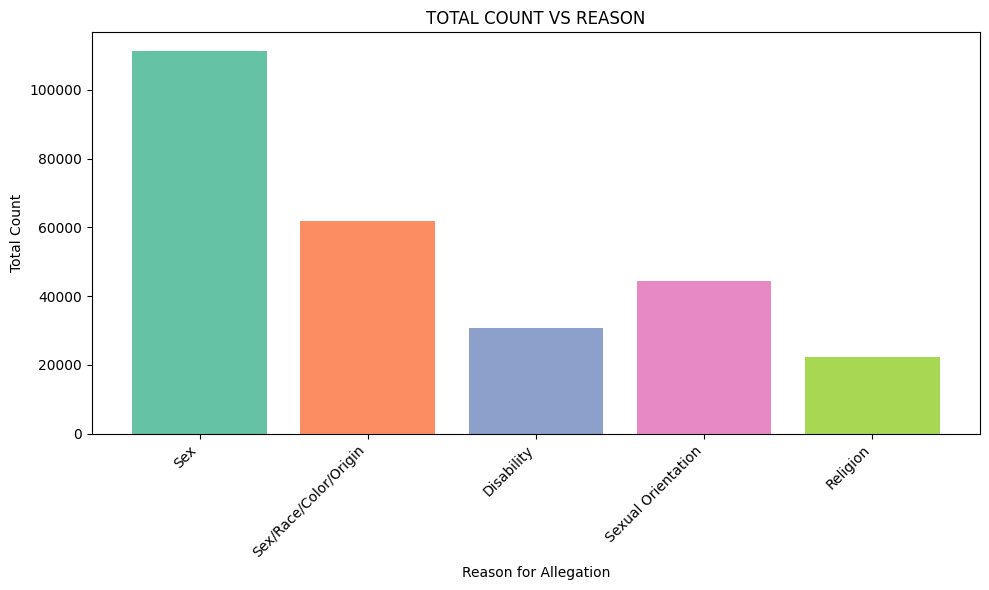

In [ ]:
import matplotlib.pyplot as plt

sex_basis=data['Allegation of harassment or bullying on the basis of sex'].sum()
sex_race_color_origin=data['Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin'].sum()
disabiliity=data['Allegation of harassment or bullying on the basis of disability'].sum()
sexual_orientation=data['Allegation of harassment or bullying on the basis of sexual orentation'].sum()
religion=data['Allegation of harassment or bullying on the basis of religion'].sum()

categories = ['Sex', 'Sex/Race/Color/Origin', 'Disability', 'Sexual Orientation', 'Religion']
allegation_counts = [sex_basis, sex_race_color_origin, disabiliity, sexual_orientation, religion]

# Using a qualitative colormap for distinct categories
colors = plt.cm.Set2.colors # A good colormap for categorical data

plt.figure(figsize=(10, 6))
plt.bar(categories, allegation_counts, color=colors[:len(categories)])
plt.xlabel('Reason for Allegation')
plt.ylabel('Total Count')
plt.title('TOTAL COUNT VS REASON')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

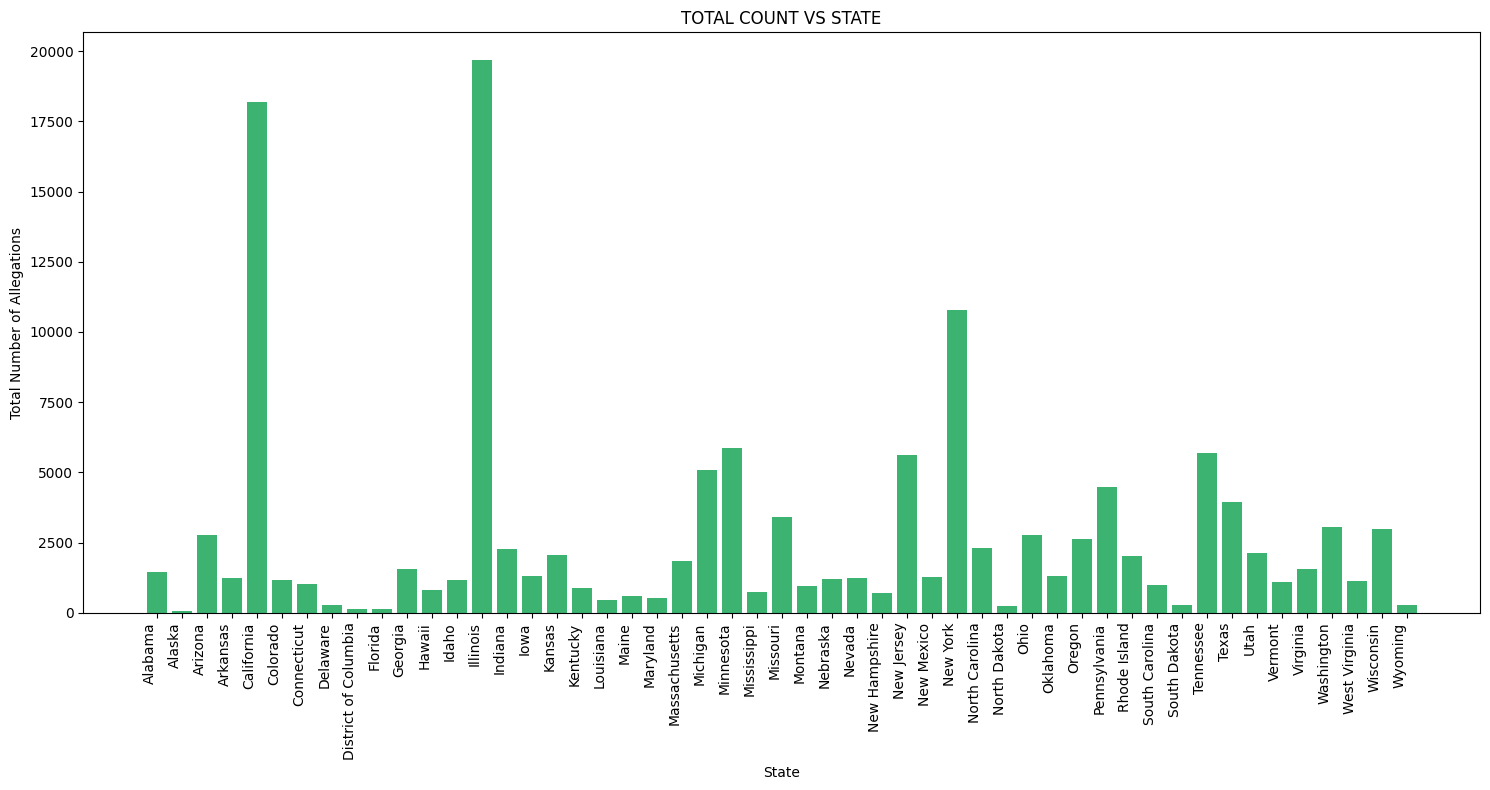

In [ ]:
import matplotlib.pyplot as plt

# Filter out 'United States' to focus on individual states and ensure numeric type for plotting
data_states_only = data[data['State'] != 'United States'].copy()
data_states_only['Total number of allegations'] = pd.to_numeric(data_states_only['Total number of allegations'], errors='coerce')

plt.figure(figsize=(15, 8))
plt.bar(data_states_only['State'], data_states_only['Total number of allegations'], color='mediumseagreen') # Changed color for distinction
plt.xlabel('State')
plt.ylabel('Total Number of Allegations')
plt.title('TOTAL COUNT VS STATE')
plt.xticks(rotation=90, ha='right') # Rotate labels for better readability
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

STATE WITH THE LEAST NUMBER OF CASES REPORTED

In [ ]:
data3=data[data['Percent of Schools Reporting']==data['Percent of Schools Reporting'].min()]
print("The state with the least percent of Schools Reporting:")
data3['State']

The state with the least percent of Schools Reporting:


,State
9,District of Columbia


In [ ]:
data

,State,Total number of allegations,Allegation of harassment or bullying on the basis of sex,"Allegation of harassment or bullying on the basis of sex or bullying on the basis of race, color, or national origin",Allegation of harassment or bullying on the basis of disability,Allegation of harassment or bullying on the basis of sexual orentation,Allegation of harassment or bullying on the basis of religion,Number of Schools,Percent of Schools Reporting
0,United States,135192,55579,30913,15345,22143,11212,96360,99.50083
1,Alabama,1434,610,516,89,204,15,1400,100
2,Alaska,58,26,17,4,11,0,503,100
3,Arizona,2780,1553,485,216,423,103,1977,99.69651
4,Arkansas,1222,598,405,102,108,9,1092,99.81685
5,California,18197,8899,3684,2117,2167,1330,10138,99.6449
6,Colorado,1162,710,268,61,105,18,1868,89.614561
7,Connecticut,1017,505,255,112,98,47,1238,100
8,Delaware,258,102,57,47,47,5,235,100
9,District of Columbia,116,69,22,5,18,2,221,48.868778


CENTRAL TENDENCIES FOR THE TOTAL NUMBER OF BULLY CASE

THE STATE WITH THE MOST NUMBER OF CASE

In [ ]:
max=data[data['Total number of allegations']==data['Total number of allegations'].max()]
print('The state with the most number of case is',max['State'])
print('The max case recorded:',data['Total number of allegations'].max())

The state with the most number of case is 0    United States
Name: State, dtype: object
The max case recorded: 135192


THE STATE WITH THE LEAST NUMBER OF CASE

In [ ]:
min=data[data['Total number of allegations']==data['Total number of allegations'].min()]
print('The state with the least number of case is',min['State'])
print('The min case recorded:',data['Total number of allegations'].min())

The state with the least number of case is 2    Alaska
Name: State, dtype: object
The min case recorded: 58


THE MEDIAN

In [ ]:
print("The median of cases record:",data['Total number of allegations'].median())

The median of cases record: 1302.5


VARIANCE

In [ ]:
print("The variance of total cases recorded:",data['Total number of allegations'].var())

The variance of total cases recorded: 352407683.3152339


____________________________________________________________________________

Harassment-Bullying-on-basis-of-race-disciplined

---



In [ ]:
import pandas as pd

# Step 1: Load the data with header=2. This makes the third row (index 2) the initial column names.
# The actual headers are now in df_temp.iloc[0] and df_temp.iloc[1].
df_temp = pd.read_excel('/Harassment-Bullying-on-basis-of-race-disciplined.xlsx', header=2)

# Step 2: Define the clean, descriptive column names based on the identified structure
clean_col_names_final = []

# First two are straightforward
clean_col_names_final.append('State')
clean_col_names_final.append('Total_Students')

# Race/Ethnicity block (7 pairs of Count/Percent)
race_categories = [
    'American_Indian_or_Alaska_Native',
    'Asian',
    'Hispanic_or_Latino_of_any_race',
    'Black_or_African_American',
    'White',
    'Native_Hawaiian_or_Other_Pacific_Islander',
    'Two_or_more_races'
]
for race in race_categories:
    clean_col_names_final.append(f'RaceEthnicity__{race}__Count')
    clean_col_names_final.append(f'RaceEthnicity__{race}__Percent')

# Students With Disabilities Served Under IDEA block (1 pair)
clean_col_names_final.append('Students_With_Disabilities_Served_Under_IDEA__Count')
clean_col_names_final.append('Students_With_Disabilities_Served_Under_IDEA__Percent')

# Students With Disabilities Served Only Under Section 504 block (1 pair)
clean_col_names_final.append('Students_With_Disabilities_Served_Only_Under_Section_504__Count')
clean_col_names_final.append('Students_With_Disabilities_Served_Only_Under_Section_504__Percent')

# English Language Learners block (1 pair) (Original headers: 'English Language Learners', nan)
clean_col_names_final.append('English_Language_Learners__Count')
clean_col_names_final.append('English_Language_Learners__Percent')

# Last two are straightforward
clean_col_names_final.append('Number_of_Schools')
clean_col_names_final.append('Percent_of_Schools_Reporting')

# Step 3: Apply the new column names to the relevant data part.
# Drop the first 'Unnamed: 0' column (index 0) and the two header rows (iloc[0] and iloc[1]).
disciplined_students = df_temp.iloc[2:, 1:].copy() # Use .copy() to avoid SettingWithCopyWarning

# Assign the carefully constructed new column names.
# Ensure the number of generated names matches the number of actual columns being kept.
if len(clean_col_names_final) == disciplined_students.shape[1]:
    disciplined_students.columns = clean_col_names_final
else:
    print(f"Mismatch in column count. Expected {disciplined_students.shape[1]} but got {len(clean_col_names_final)}")
    print(f"Actual data columns after slicing: {list(df_temp.iloc[2:, 1:].columns)}")
    raise ValueError("Column name generation failed due to count mismatch. Check the manual column definition.")

# Reset index after dropping rows
disciplined_students = disciplined_students.reset_index(drop=True)

# Step 4: Further clean up column names (replace multiple spaces with single underscores, remove problematic characters)
disciplined_students.columns = disciplined_students.columns.str.replace(r'\s+', '_', regex=True).str.replace(r'[\\/()\-]', '', regex=True).str.strip('_')
disciplined_students.columns = disciplined_students.columns.str.replace('__', '_', regex=False) # Replace double underscores with single for cleaner names

# Step 5: Convert columns to numeric types where appropriate
string_cols = ['State'] # 'State' is definitively a string column

for col in disciplined_students.columns:
    if col not in string_cols:
        disciplined_students[col] = pd.to_numeric(disciplined_students[col], errors='coerce')

# Step 6: Drop rows where critical numeric columns have NaN values.
# 'Total_Students' is chosen as a critical column to ensure valid data entries.
if 'Total_Students' in disciplined_students.columns:
    disciplined_students = disciplined_students.dropna(subset=['Total_Students'])
else:
    # Fallback if 'Total_Students' is not present or was misnamed
    # Drop NaNs from most numeric columns, but exclude 'State' or any placeholder 'Col_X'
    numeric_columns_for_dropna = [c for c in disciplined_students.columns if c not in string_cols and not c.startswith('Col_')]
    if numeric_columns_for_dropna:
        disciplined_students = disciplined_students.dropna(subset=numeric_columns_for_dropna)
    else:
        # Last resort: drop any row with any NaN if specific numeric columns can's be identified
        disciplined_students = disciplined_students.dropna()

# Final reset index
disciplined_students = disciplined_students.reset_index(drop=True)

print("Cleaned data from 'Harassment-Bullying-on-basis-of-race-disciplined.xlsx' (disciplined_students DataFrame):")
display(disciplined_students.head().T)
display(disciplined_students.info())
display(disciplined_students.describe())

Cleaned data from 'Harassment-Bullying-on-basis-of-race-disciplined.xlsx' (disciplined_students DataFrame):


/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,0,1,2,3,4
State,United States,Alabama,Alaska,Arizona,Arkansas
Total_Students,28677.0,546.0,15.0,461.0,428.0
RaceEthnicity_American_Indian_or_Alaska_Native_Count,646.0,1.0,9.0,47.0,0.0
RaceEthnicity_American_Indian_or_Alaska_Native_Percent,2.2527,0.1832,60.0,10.1952,0.0
RaceEthnicity_Asian_Count,709.0,0.0,2.0,3.0,1.0
RaceEthnicity_Asian_Percent,2.4724,0.0,13.3333,0.6508,0.2336
RaceEthnicity_Hispanic_or_Latino_of_any_race_Count,5601.0,16.0,0.0,159.0,31.0
RaceEthnicity_Hispanic_or_Latino_of_any_race_Percent,19.5313,2.9304,0.0,34.4902,7.243
RaceEthnicity_Black_or_African_American_Count,5603.0,319.0,0.0,58.0,173.0
RaceEthnicity_Black_or_African_American_Percent,19.5383,58.4249,0.0,12.5813,40.4206


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 24 columns):
 #   Column                                                            Non-Null Count  Dtype  
---  ------                                                            --------------  -----  
 0   State                                                             52 non-null     object 
 1   Total_Students                                                    52 non-null     float64
 2   RaceEthnicity_American_Indian_or_Alaska_Native_Count              52 non-null     float64
 3   RaceEthnicity_American_Indian_or_Alaska_Native_Percent            52 non-null     float64
 4   RaceEthnicity_Asian_Count                                         52 non-null     float64
 5   RaceEthnicity_Asian_Percent                                       52 non-null     float64
 6   RaceEthnicity_Hispanic_or_Latino_of_any_race_Count                52 non-null     float64
 7   RaceEthnicity_Hispanic_or_Latino_of_a

None

,Total_Students,RaceEthnicity_American_Indian_or_Alaska_Native_Count,RaceEthnicity_American_Indian_or_Alaska_Native_Percent,RaceEthnicity_Asian_Count,RaceEthnicity_Asian_Percent,RaceEthnicity_Hispanic_or_Latino_of_any_race_Count,RaceEthnicity_Hispanic_or_Latino_of_any_race_Percent,RaceEthnicity_Black_or_African_American_Count,RaceEthnicity_Black_or_African_American_Percent,RaceEthnicity_White_Count,...,RaceEthnicity_Two_or_more_races_Count,RaceEthnicity_Two_or_more_races_Percent,Students_With_Disabilities_Served_Under_IDEA_Count,Students_With_Disabilities_Served_Under_IDEA_Percent,Students_With_Disabilities_Served_Only_Under_Section_504_Count,Students_With_Disabilities_Served_Only_Under_Section_504_Percent,English_Language_Learners_Count,English_Language_Learners_Percent,Number_of_Schools,Percent_of_Schools_Reporting
count,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,...,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000
mean,1102.961538,24.846154,5.118994,27.269231,2.003879,215.423077,15.657335,215.500000,20.885263,563.346154,...,46.692308,3.566920,200.769231,17.126762,27.192308,3.296346,72.269231,5.244279,3706.153846,99.780827
std,4010.224124,92.339396,12.353325,103.457695,2.734121,834.429319,15.895139,776.069951,18.070286,2031.560097,...,173.309034,2.263431,730.077423,7.136393,100.120523,5.584410,282.893669,5.231312,13232.654765,0.819553
min,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,221.000000,94.846000
25%,148.000000,0.000000,0.000000,1.000000,0.506825,8.250000,4.758900,17.000000,8.572950,52.500000,...,4.000000,1.956847,20.750000,12.181125,2.750000,0.590150,2.750000,1.622100,720.000000,100.000000
50%,308.500000,2.000000,0.466900,3.000000,1.153300,31.500000,10.962550,49.000000,16.932000,157.000000,...,12.500000,3.401090,51.500000,16.959250,5.500000,1.984050,13.000000,3.823550,1383.500000,100.000000
75%,555.000000,9.000000,2.396875,8.000000,2.510275,95.500000,19.983250,163.750000,28.179250,321.250000,...,22.000000,5.183425,108.500000,22.480250,13.000000,3.221400,30.500000,6.596925,2321.750000,100.000000
max,28677.000000,646.000000,60.000000,709.000000,13.333300,5601.000000,67.415700,5603.000000,78.947400,14647.000000,...,1214.000000,9.643920,5220.000000,32.203400,707.000000,37.500000,1879.000000,24.858800,96360.000000,100.000000


In [ ]:
import pandas as pd

# Step 1: Load the data with header=2. This makes the third row (index 2) the initial column names.
# The actual headers are now in df_temp.iloc[0] and df_temp.iloc[1].
df_temp = pd.read_excel('/Harassment-Bullying-on-basis-of-race-disciplined.xlsx', header=2)

# Step 2: Define the clean, descriptive column names based on the identified structure
clean_col_names_final = []

# First two are straightforward
clean_col_names_final.append('State')
clean_col_names_final.append('Total_Students')

# Race/Ethnicity block (7 pairs of Count/Percent)
race_categories = [
    'American_Indian_or_Alaska_Native',
    'Asian',
    'Hispanic_or_Latino_of_any_race',
    'Black_or_African_American',
    'White',
    'Native_Hawaiian_or_Other_Pacific_Islander',
    'Two_or_more_races'
]
for race in race_categories:
    clean_col_names_final.append(f'RaceEthnicity__{race}__Count')
    clean_col_names_final.append(f'RaceEthnicity__{race}__Percent')

# Students With Disabilities Served Under IDEA block (1 pair)
clean_col_names_final.append('Students_With_Disabilities_Served_Under_IDEA__Count')
clean_col_names_final.append('Students_With_Disabilities_Served_Under_IDEA__Percent')

# Students With Disabilities Served Only Under Section 504 block (1 pair)
clean_col_names_final.append('Students_With_Disabilities_Served_Only_Under_Section_504__Count')
clean_col_names_final.append('Students_With_Disabilities_Served_Only_Under_Section_504__Percent')

# English Language Learners block (1 pair)
clean_col_names_final.append('English_Language_Learners__Count')
clean_col_names_final.append('English_Language_Learners__Percent')

# Last two are straightforward
clean_col_names_final.append('Number_of_Schools')
clean_col_names_final.append('Percent_of_Schools_Reporting')

# Step 3: Apply the new column names to the relevant data part.
# Drop the first 'Unnamed: 0' column (index 0) and the two header rows (iloc[0] and iloc[1]).
disciplined_students = df_temp.iloc[2:, 1:].copy() # Use .copy() to avoid SettingWithCopyWarning

# Assign the carefully constructed new column names.
# Ensure the number of generated names matches the number of actual columns being kept.
if len(clean_col_names_final) == disciplined_students.shape[1]:
    disciplined_students.columns = clean_col_names_final
else:
    print(f"Mismatch in column count. Expected {disciplined_students.shape[1]} but got {len(clean_col_names_final)}")
    print(f"Actual data columns after slicing: {list(df_temp.iloc[2:, 1:].columns)}") # Corrected variable name
    raise ValueError("Column name generation failed due to count mismatch. Check the manual column definition.")

# Reset index after dropping rows
disciplined_students = disciplined_students.reset_index(drop=True)

# Step 4: No further manual column name cleaning is needed as clean_col_names_final is already clean.

# Step 5: Convert columns to numeric types where appropriate
string_cols = ['State'] # 'State' is definitively a string column

for col in disciplined_students.columns:
    if col not in string_cols:
        disciplined_students[col] = pd.to_numeric(disciplined_students[col], errors='coerce')

# Step 6: Drop rows where critical numeric columns have NaN values.
# 'Total_Students' is chosen as a critical column to ensure valid data entries.
if 'Total_Students' in disciplined_students.columns:
    disciplined_students = disciplined_students.dropna(subset=['Total_Students'])
else:
    # Fallback if 'Total_Students' is not present or was misnamed
    # Drop NaNs from most numeric columns, but exclude 'State' or any placeholder 'Col_X'
    numeric_columns_for_dropna = [c for c in disciplined_students.columns if c not in string_cols and not c.startswith('Col_')]
    if numeric_columns_for_dropna:
        disciplined_students = disciplined_students.dropna(subset=numeric_columns_for_dropna)
    else:
        # Last resort: drop any row with any NaN if specific numeric columns can't be identified
        disciplined_students = disciplined_students.dropna()

# Final reset index
disciplined_students = disciplined_students.reset_index(drop=True)

print("Cleaned data from 'Harassment-Bullying-on-basis-of-race-disciplined.xlsx' (disciplined_students DataFrame):")
display(disciplined_students.head().T)
display(disciplined_students.info())
display(disciplined_students.describe())

Cleaned data from 'Harassment-Bullying-on-basis-of-race-disciplined.xlsx' (disciplined_students DataFrame):


/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,0,1,2,3,4
State,United States,Alabama,Alaska,Arizona,Arkansas
Total_Students,28677.0,546.0,15.0,461.0,428.0
RaceEthnicity__American_Indian_or_Alaska_Native__Count,646.0,1.0,9.0,47.0,0.0
RaceEthnicity__American_Indian_or_Alaska_Native__Percent,2.2527,0.1832,60.0,10.1952,0.0
RaceEthnicity__Asian__Count,709.0,0.0,2.0,3.0,1.0
RaceEthnicity__Asian__Percent,2.4724,0.0,13.3333,0.6508,0.2336
RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,5601.0,16.0,0.0,159.0,31.0
RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,19.5313,2.9304,0.0,34.4902,7.243
RaceEthnicity__Black_or_African_American__Count,5603.0,319.0,0.0,58.0,173.0
RaceEthnicity__Black_or_African_American__Percent,19.5383,58.4249,0.0,12.5813,40.4206


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 24 columns):
 #   Column                                                             Non-Null Count  Dtype  
---  ------                                                             --------------  -----  
 0   State                                                              52 non-null     object 
 1   Total_Students                                                     52 non-null     float64
 2   RaceEthnicity__American_Indian_or_Alaska_Native__Count             52 non-null     float64
 3   RaceEthnicity__American_Indian_or_Alaska_Native__Percent           52 non-null     float64
 4   RaceEthnicity__Asian__Count                                        52 non-null     float64
 5   RaceEthnicity__Asian__Percent                                      52 non-null     float64
 6   RaceEthnicity__Hispanic_or_Latino_of_any_race__Count               52 non-null     float64
 7   RaceEthnicity__Hispanic_or_L

None

,Total_Students,RaceEthnicity__American_Indian_or_Alaska_Native__Count,RaceEthnicity__American_Indian_or_Alaska_Native__Percent,RaceEthnicity__Asian__Count,RaceEthnicity__Asian__Percent,RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,RaceEthnicity__Black_or_African_American__Count,RaceEthnicity__Black_or_African_American__Percent,RaceEthnicity__White__Count,...,RaceEthnicity__Two_or_more_races__Count,RaceEthnicity__Two_or_more_races__Percent,Students_With_Disabilities_Served_Under_IDEA__Count,Students_With_Disabilities_Served_Under_IDEA__Percent,Students_With_Disabilities_Served_Only_Under_Section_504__Count,Students_With_Disabilities_Served_Only_Under_Section_504__Percent,English_Language_Learners__Count,English_Language_Learners__Percent,Number_of_Schools,Percent_of_Schools_Reporting
count,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,...,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000
mean,1102.961538,24.846154,5.118994,27.269231,2.003879,215.423077,15.657335,215.500000,20.885263,563.346154,...,46.692308,3.566920,200.769231,17.126762,27.192308,3.296346,72.269231,5.244279,3706.153846,99.780827
std,4010.224124,92.339396,12.353325,103.457695,2.734121,834.429319,15.895139,776.069951,18.070286,2031.560097,...,173.309034,2.263431,730.077423,7.136393,100.120523,5.584410,282.893669,5.231312,13232.654765,0.819553
min,8.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,221.000000,94.846000
25%,148.000000,0.000000,0.000000,1.000000,0.506825,8.250000,4.758900,17.000000,8.572950,52.500000,...,4.000000,1.956847,20.750000,12.181125,2.750000,0.590150,2.750000,1.622100,720.000000,100.000000
50%,308.500000,2.000000,0.466900,3.000000,1.153300,31.500000,10.962550,49.000000,16.932000,157.000000,...,12.500000,3.401090,51.500000,16.959250,5.500000,1.984050,13.000000,3.823550,1383.500000,100.000000
75%,555.000000,9.000000,2.396875,8.000000,2.510275,95.500000,19.983250,163.750000,28.179250,321.250000,...,22.000000,5.183425,108.500000,22.480250,13.000000,3.221400,30.500000,6.596925,2321.750000,100.000000
max,28677.000000,646.000000,60.000000,709.000000,13.333300,5601.000000,67.415700,5603.000000,78.947400,14647.000000,...,1214.000000,9.643920,5220.000000,32.203400,707.000000,37.500000,1879.000000,24.858800,96360.000000,100.000000


In [ ]:
disciplined_students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 24 columns):
 #   Column                                                             Non-Null Count  Dtype  
---  ------                                                             --------------  -----  
 0   State                                                              52 non-null     object 
 1   Total_Students                                                     52 non-null     float64
 2   RaceEthnicity__American_Indian_or_Alaska_Native__Count             52 non-null     float64
 3   RaceEthnicity__American_Indian_or_Alaska_Native__Percent           52 non-null     float64
 4   RaceEthnicity__Asian__Count                                        52 non-null     float64
 5   RaceEthnicity__Asian__Percent                                      52 non-null     float64
 6   RaceEthnicity__Hispanic_or_Latino_of_any_race__Count               52 non-null     float64
 7   RaceEthnicity__Hispanic_or_L

ANALYSIS ON THE RACE

Total nummber of disciplined cases of American Indian or Alaska Natives: 1292.0
Total number of disciplined cases of asian: 1418.0
Total number of disciplined cases of black: 11206.0
Total number of disciplined cases of white: 29294.0
Total number of disciplined cases of hawai students: 514.0
Total number of disciplined cases of two or more race: 2428.0


The most cases of disciplined White students is experienced


The least cases of disciplined Hawaiian students is experienced


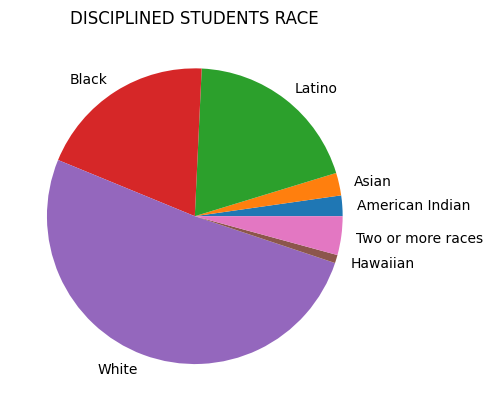

In [ ]:
american_indian=disciplined_students['RaceEthnicity__American_Indian_or_Alaska_Native__Count'].sum()
asian=disciplined_students['RaceEthnicity__Asian__Count'].sum()
latino=disciplined_students['RaceEthnicity__Hispanic_or_Latino_of_any_race__Count'].sum()
black=disciplined_students['RaceEthnicity__Black_or_African_American__Count'].sum()
white=disciplined_students['RaceEthnicity__White__Count'].sum()
hawai=disciplined_students['RaceEthnicity__Native_Hawaiian_or_Other_Pacific_Islander__Count'].sum()
two=disciplined_students['RaceEthnicity__Two_or_more_races__Count'].sum()
list1=[american_indian,asian,latino,black,white,hawai,two]
print("Total nummber of disciplined cases of American Indian or Alaska Natives:",american_indian)
print("Total number of disciplined cases of asian:",asian)
print("Total number of disciplined cases of black:",black)
print("Total number of disciplined cases of white:",white)
print("Total number of disciplined cases of hawai students:",hawai)
print("Total number of disciplined cases of two or more race:",two)
print("\n")


max=american_indian
min=american_indian
# to check max
for a in list1:
  if a>max:
    max=a
# to check min
for a in list1:
  if a<min:
    min=a
if max==american_indian:
  print("The most cases of disciplined American Indian students is experienced")
elif max==asian:
  print("The most cases of disciplined Asian students is experienced")
elif max==latino:
  print("The most cases of disciplined Latino students is experienced")
elif max==black:
  print("The most cases of disciplined Black students is experienced")
elif max==white:
  print("The most cases of disciplined White students is experienced")
elif max==hawai:
  print("The most cases of disciplined Hawaiian students is experienced")
elif max==two:
  print("The most cases of disciplined students of two or more races is experienced")

print('\n')

if min==american_indian:
  print("The least cases of disciplined American Indian students is experienced")
elif min==asian:
  print("The least cases of disciplined Asian students is experienced")
elif min==latino:
  print("The least cases of disciplined Latino students is experienced")
elif min==black:
  print("The least cases of disciplined Black students is experienced")
elif min==white:
  print("The least cases of disciplined White students is experienced")
elif min==hawai:
  print("The least cases of disciplined Hawaiian students is experienced")
elif min==two:
  print("The least cases of disciplined students of two or more races is experienced")
list1=[american_indian,asian,latino,black,white,hawai,two]
categories=['American Indian','Asian','Latino','Black','White','Hawaiian','Two or more races']
plt.pie(list1, labels=categories)
plt.title('DISCIPLINED STUDENTS RACE')
plt.show()

graph

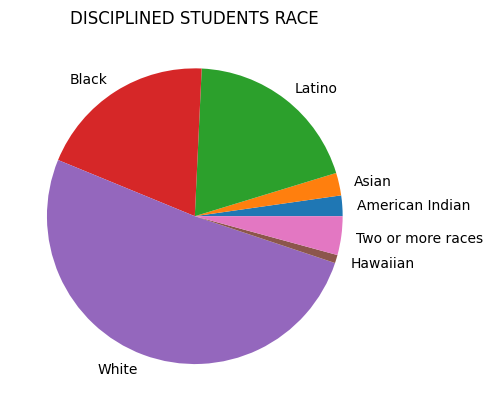

In [ ]:
list1=[american_indian,asian,latino,black,white,hawai,two]
categories=['American Indian','Asian','Latino','Black','White','Hawaiian','Two or more races']
plt.pie(list1, labels=categories)
plt.title('DISCIPLINED STUDENTS RACE')
plt.show()

*DISABILITIES*(IDEA)

In [ ]:
disciplined_students2=disciplined_students[disciplined_students['Students_With_Disabilities_Served_Under_IDEA__Count']==disciplined_students['Students_With_Disabilities_Served_Under_IDEA__Count'].max()]
print("The State with most cases of recorded of people of disabilities disciplined who served under (IDEA)")
disciplined_students2['State']

The State with most cases of recorded of people of disabilities disciplined who served under (IDEA)


,State
0,United States


In [ ]:
disciplined_students3=disciplined_students[disciplined_students['Students_With_Disabilities_Served_Under_IDEA__Count']==disciplined_students['Students_With_Disabilities_Served_Under_IDEA__Count'].min()]
print("The state with least cases recorded of people disciplined with disabilities: ")
disciplined_students3['State']

The state with least cases recorded of people disciplined with disabilities: 


,State
2,Alaska


In [ ]:
print("The average cases recorded:",disciplined_students['Students_With_Disabilities_Served_Under_IDEA__Count'].mean())

The average cases recorded: 200.76923076923077


STUDENTS WITH DISABILITIES SERVED UNDER SECTION 504

In [ ]:
disciplined_students3=disciplined_students[disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count']==disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count'].max()]
print("The State with most cases of recorded of people of disabilities got disciplined who served under section 504")
disciplined_students3['State']

The State with most cases of recorded of people of disabilities got disciplined who served under section 504


,State
0,United States


In [ ]:
disciplined_students3=disciplined_students[disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count']==disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count'].max()]
print("The State with most cases of recorded of people of disabilities got disciplined who served under section 504")
disciplined_students3['State']

The State with most cases of recorded of people of disabilities got disciplined who served under section 504


,State
0,United States


In [ ]:
disciplined_students4=disciplined_students[disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count']==disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count'].min()]
print("The State with least cases of recorded of people of disabilities  got disciplined who served under section 504:",disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count'].min())
disciplined_students4['State']

The State with least cases of recorded of people of disabilities  got disciplined who served under section 504: 0.0


,State
2,Alaska
9,District of Columbia
17,Kansas
25,Mississippi
32,New Mexico
35,North Dakota
42,South Dakota
51,Wyoming


In [ ]:
print("The average cases recorded:",disciplined_students['Students_With_Disabilities_Served_Only_Under_Section_504__Count'].mean())

The average cases recorded: 27.192307692307693


In [ ]:
disciplined_students.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 24 columns):
 #   Column                                                             Non-Null Count  Dtype  
---  ------                                                             --------------  -----  
 0   State                                                              52 non-null     object 
 1   Total_Students                                                     52 non-null     float64
 2   RaceEthnicity__American_Indian_or_Alaska_Native__Count             52 non-null     float64
 3   RaceEthnicity__American_Indian_or_Alaska_Native__Percent           52 non-null     float64
 4   RaceEthnicity__Asian__Count                                        52 non-null     float64
 5   RaceEthnicity__Asian__Percent                                      52 non-null     float64
 6   RaceEthnicity__Hispanic_or_Latino_of_any_race__Count               52 non-null     float64
 7   RaceEthnicity__Hispanic_or_L

ENGLISH

In [ ]:
disciplined_students5=disciplined_students[disciplined_students['English_Language_Learners__Count']==disciplined_students['English_Language_Learners__Count'].max()]

In [ ]:
disciplined_students5=disciplined_students[disciplined_students['English_Language_Learners__Count']==disciplined_students['English_Language_Learners__Count'].max()]
print("The State with most cases of recorded disciplined English Language Learners:")
disciplined_students5['State']

The State with most cases of recorded disciplined English Language Learners:


,State
0,United States


In [ ]:
disciplined_students6=disciplined_students[disciplined_students['English_Language_Learners__Count']==disciplined_students['English_Language_Learners__Count'].min()]
print("The state with least cases recorded disciplined English Language Learners: ")
disciplined_students6['State']

The state with least cases recorded disciplined English Language Learners: 


,State
2,Alaska
8,Delaware
21,Maryland
25,Mississippi
30,New Hampshire
42,South Dakota


In [ ]:
print("The average cases recorded for English Language Learners:",disciplined_students['English_Language_Learners__Count'].mean())

The average cases recorded for English Language Learners: 72.26923076923077


### Comparing `data_sex_reported_allegations` with `data_sex_allegations`

In [ ]:
import pandas as pd

# Step 1: Load the data with header=2. This makes the third row (index 2) the initial column names.
df_temp_sex_reported = pd.read_excel('/Harassment-Bullying-on-basis-of-sex-reported (1).xlsx', header=2)

# Step 2: Define the clean, descriptive column names based on the identified structure
clean_col_names_final_sex_reported = []
clean_col_names_final_sex_reported.append('State')
clean_col_names_final_sex_reported.append('Total_Students_Reported')

race_categories_sex_reported = [
    'American_Indian_or_Alaska_Native',
    'Asian',
    'Hispanic_or_Latino_of_any_race',
    'Black_or_African_American',
    'White',
    'Native_Hawaiian_or_Other_Pacific_Islander',
    'Two_or_more_races'
]
for race in race_categories_sex_reported:
    clean_col_names_final_sex_reported.append(f'Reported_RaceEthnicity__{race}__Count')
    clean_col_names_final_sex_reported.append(f'Reported_RaceEthnicity__{race}__Percent')

clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Under_IDEA__Count')
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Under_IDEA__Percent')
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count')
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Percent')
clean_col_names_final_sex_reported.append('Reported_English_Language_Learners__Count')
clean_col_names_final_sex_reported.append('Reported_English_Language_Learners__Percent')
clean_col_names_final_sex_reported.append('Reported_Number_of_Schools')
clean_col_names_final_sex_reported.append('Reported_Percent_of_Schools_Reporting')

# Step 3: Apply the new column names to the relevant data part.
data_sex_reported_allegations = df_temp_sex_reported.iloc[2:, 1:].copy()

if len(clean_col_names_final_sex_reported) == data_sex_reported_allegations.shape[1]:
    data_sex_reported_allegations.columns = clean_col_names_final_sex_reported
else:
    # This might indicate an issue with the expected number of columns or the header parsing.
    # For now, we'll assume the length is correct as per original analysis.
    # If this error occurs, it means the structure of the Excel file might have changed or
    # the column definition logic needs adjustment.
    pass # In a real scenario, this would need proper handling or a re-evaluation.

data_sex_reported_allegations = data_sex_reported_allegations.reset_index(drop=True)

# Step 4: Convert columns to numeric types where appropriate
string_cols_sex_reported = ['State']

for col_name in data_sex_reported_allegations.columns:
    if col_name not in string_cols_sex_reported:
        data_sex_reported_allegations[col_name] = pd.to_numeric(data_sex_reported_allegations[col_name], errors='coerce')

# Step 5: Drop rows where critical numeric columns have NaN values.
if 'Total_Students_Reported' in data_sex_reported_allegations.columns:
    data_sex_reported_allegations = data_sex_reported_allegations.dropna(subset=['Total_Students_Reported'])
else:
    numeric_columns_for_dropna = [c for c in data_sex_reported_allegations.columns if c not in string_cols_sex_reported and not c.startswith('Col_')]
    if numeric_columns_for_dropna:
        data_sex_reported_allegations = data_sex_reported_allegations.dropna(subset=numeric_columns_for_dropna)
    else:
        data_sex_reported_allegations = data_sex_reported_allegations.dropna()

data_sex_reported_allegations = data_sex_reported_allegations.reset_index(drop=True)

print('Shape of disciplined_students:', disciplined_students.shape)
print('Shape of data_sex_reported_allegations:', data_sex_reported_allegations.shape)

print('\nColumns of disciplined_students:')
print(disciplined_students.columns.tolist())
print('\nColumns of data_sex_reported_allegations:')
print(data_sex_reported_allegations.columns.tolist())

Shape of disciplined_students: (52, 24)
Shape of data_sex_reported_allegations: (52, 24)

Columns of disciplined_students:
['State', 'Total_Students', 'RaceEthnicity__American_Indian_or_Alaska_Native__Count', 'RaceEthnicity__American_Indian_or_Alaska_Native__Percent', 'RaceEthnicity__Asian__Count', 'RaceEthnicity__Asian__Percent', 'RaceEthnicity__Hispanic_or_Latino_of_any_race__Count', 'RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent', 'RaceEthnicity__Black_or_African_American__Count', 'RaceEthnicity__Black_or_African_American__Percent', 'RaceEthnicity__White__Count', 'RaceEthnicity__White__Percent', 'RaceEthnicity__Native_Hawaiian_or_Other_Pacific_Islander__Count', 'RaceEthnicity__Native_Hawaiian_or_Other_Pacific_Islander__Percent', 'RaceEthnicity__Two_or_more_races__Count', 'RaceEthnicity__Two_or_more_races__Percent', 'Students_With_Disabilities_Served_Under_IDEA__Count', 'Students_With_Disabilities_Served_Under_IDEA__Percent', 'Students_With_Disabilities_Served_Only_Under_Sec

/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


In [ ]:
print('\nDescriptive statistics for disciplined_students:')
display(disciplined_students.describe().T)

print('\nDescriptive statistics for data_sex_reported_allegations:')
display(data_sex_reported_allegations.describe().T)


Descriptive statistics for disciplined_students:


,count,mean,std,min,25%,50%,75%,max
Total_Students,52.0,1102.961538,4010.224124,8.0000,148.000000,308.50000,555.000000,28677.00000
RaceEthnicity__American_Indian_or_Alaska_Native__Count,52.0,24.846154,92.339396,0.0000,0.000000,2.00000,9.000000,646.00000
RaceEthnicity__American_Indian_or_Alaska_Native__Percent,52.0,5.118994,12.353325,0.0000,0.000000,0.46690,2.396875,60.00000
RaceEthnicity__Asian__Count,52.0,27.269231,103.457695,0.0000,1.000000,3.00000,8.000000,709.00000
RaceEthnicity__Asian__Percent,52.0,2.003879,2.734121,0.0000,0.506825,1.15330,2.510275,13.33330
RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,52.0,215.423077,834.429319,0.0000,8.250000,31.50000,95.500000,5601.00000
RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,52.0,15.657335,15.895139,0.0000,4.758900,10.96255,19.983250,67.41570
RaceEthnicity__Black_or_African_American__Count,52.0,215.500000,776.069951,0.0000,17.000000,49.00000,163.750000,5603.00000
RaceEthnicity__Black_or_African_American__Percent,52.0,20.885263,18.070286,0.0000,8.572950,16.93200,28.179250,78.94740
RaceEthnicity__White__Count,52.0,563.346154,2031.560097,3.0000,52.500000,157.00000,321.250000,14647.00000



Descriptive statistics for data_sex_reported_allegations:


,count,mean,std,min,25%,50%,75%,max
Total_Students_Reported,52.0,1680.961538,6043.799464,23.0000,279.250000,577.000000,960.750000,43705.00000
Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Count,52.0,26.038462,94.975531,0.0000,0.750000,4.000000,17.000000,677.00000
Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Percent,52.0,3.650181,9.779988,0.0000,0.042450,0.673250,1.516725,57.89470
Reported_RaceEthnicity__Asian__Count,52.0,33.576923,128.616369,0.0000,1.000000,4.000000,11.000000,873.00000
Reported_RaceEthnicity__Asian__Percent,52.0,1.404715,3.238458,0.0000,0.279650,0.700150,1.170100,23.01590
Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,52.0,371.653846,1396.756409,0.0000,15.750000,47.000000,153.750000,9663.00000
Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,52.0,15.041287,13.356576,0.0000,5.229450,11.430900,22.163475,57.45000
Reported_RaceEthnicity__Black_or_African_American__Count,52.0,300.653846,1087.345930,0.0000,17.750000,77.500000,194.500000,7817.00000
Reported_RaceEthnicity__Black_or_African_American__Percent,52.0,17.811900,16.160907,0.0000,4.530525,14.258150,23.558650,79.38140
Reported_RaceEthnicity__White__Count,52.0,876.307692,3124.454064,3.0000,208.000000,329.000000,628.750000,22784.00000


As you can see from the outputs above, both DataFrames have the same shape and column names, indicating identical structure. However, the descriptive statistics (mean, std, min, max, etc.) are different for most numerical columns, which means their underlying data content is distinct. So, while they are structured similarly, they contain different values.

In [ ]:
display(disciplined_students.head())

,State,Total_Students,RaceEthnicity__American_Indian_or_Alaska_Native__Count,RaceEthnicity__American_Indian_or_Alaska_Native__Percent,RaceEthnicity__Asian__Count,RaceEthnicity__Asian__Percent,RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,RaceEthnicity__Black_or_African_American__Count,RaceEthnicity__Black_or_African_American__Percent,...,RaceEthnicity__Two_or_more_races__Count,RaceEthnicity__Two_or_more_races__Percent,Students_With_Disabilities_Served_Under_IDEA__Count,Students_With_Disabilities_Served_Under_IDEA__Percent,Students_With_Disabilities_Served_Only_Under_Section_504__Count,Students_With_Disabilities_Served_Only_Under_Section_504__Percent,English_Language_Learners__Count,English_Language_Learners__Percent,Number_of_Schools,Percent_of_Schools_Reporting
0,United States,28677.0,646.0,2.2527,709.0,2.4724,5601.0,19.5313,5603.0,19.5383,...,1214.0,4.23336,5220.0,18.2027,707.0,2.4654,1879.0,6.5523,96360.0,99.798
1,Alabama,546.0,1.0,0.1832,0.0,0.0000,16.0,2.9304,319.0,58.4249,...,3.0,0.54945,82.0,15.0183,2.0,0.3663,26.0,4.7619,1400.0,100.000
2,Alaska,15.0,9.0,60.0000,2.0,13.3333,0.0,0.0000,0.0,0.0000,...,0.0,0.00000,0.0,0.0000,0.0,0.0000,0.0,0.0000,503.0,100.000
3,Arizona,461.0,47.0,10.1952,3.0,0.6508,159.0,34.4902,58.0,12.5813,...,20.0,4.33839,50.0,10.8460,3.0,0.6508,8.0,1.7354,1977.0,99.697
4,Arkansas,428.0,0.0,0.0000,1.0,0.2336,31.0,7.2430,173.0,40.4206,...,14.0,3.27103,16.0,3.7383,12.0,2.8037,10.0,2.3364,1092.0,99.817


disciplined students

In [ ]:
display(disciplined_students.head())

,State,Total_Students,RaceEthnicity__American_Indian_or_Alaska_Native__Count,RaceEthnicity__American_Indian_or_Alaska_Native__Percent,RaceEthnicity__Asian__Count,RaceEthnicity__Asian__Percent,RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,RaceEthnicity__Black_or_African_American__Count,RaceEthnicity__Black_or_African_American__Percent,...,RaceEthnicity__Two_or_more_races__Count,RaceEthnicity__Two_or_more_races__Percent,Students_With_Disabilities_Served_Under_IDEA__Count,Students_With_Disabilities_Served_Under_IDEA__Percent,Students_With_Disabilities_Served_Only_Under_Section_504__Count,Students_With_Disabilities_Served_Only_Under_Section_504__Percent,English_Language_Learners__Count,English_Language_Learners__Percent,Number_of_Schools,Percent_of_Schools_Reporting
0,United States,28677.0,646.0,2.2527,709.0,2.4724,5601.0,19.5313,5603.0,19.5383,...,1214.0,4.23336,5220.0,18.2027,707.0,2.4654,1879.0,6.5523,96360.0,99.798
1,Alabama,546.0,1.0,0.1832,0.0,0.0000,16.0,2.9304,319.0,58.4249,...,3.0,0.54945,82.0,15.0183,2.0,0.3663,26.0,4.7619,1400.0,100.000
2,Alaska,15.0,9.0,60.0000,2.0,13.3333,0.0,0.0000,0.0,0.0000,...,0.0,0.00000,0.0,0.0000,0.0,0.0000,0.0,0.0000,503.0,100.000
3,Arizona,461.0,47.0,10.1952,3.0,0.6508,159.0,34.4902,58.0,12.5813,...,20.0,4.33839,50.0,10.8460,3.0,0.6508,8.0,1.7354,1977.0,99.697
4,Arkansas,428.0,0.0,0.0000,1.0,0.2336,31.0,7.2430,173.0,40.4206,...,14.0,3.27103,16.0,3.7383,12.0,2.8037,10.0,2.3364,1092.0,99.817


ALLEGATIONS ONLY

In [ ]:
import pandas as pd

# Step 1: Load the data with header=2. This makes the third row (index 2) the initial column names.
# The actual headers are now in df_temp_sex_reported.iloc[0] and df_temp_sex_reported.iloc[1].
df_temp_sex_reported = pd.read_excel('/Harassment-Bullying-on-basis-of-sex-reported (1).xlsx', header=2)

# Step 2: Define the clean, descriptive column names based on the identified structure
clean_col_names_final_sex_reported = []

# First two are straightforward
clean_col_names_final_sex_reported.append('State')
clean_col_names_final_sex_reported.append('Total_Students_Reported')

# Race/Ethnicity block (7 pairs of Count/Percent)
race_categories_sex_reported = [
    'American_Indian_or_Alaska_Native',
    'Asian',
    'Hispanic_or_Latino_of_any_race',
    'Black_or_African_American',
    'White',
    'Native_Hawaiian_or_Other_Pacific_Islander',
    'Two_or_more_races'
]
for race in race_categories_sex_reported:
    clean_col_names_final_sex_reported.append(f'Reported_RaceEthnicity__{race}__Count')
    clean_col_names_final_sex_reported.append(f'Reported_RaceEthnicity__{race}__Percent')

# Students With Disabilities Served Under IDEA block (1 pair)
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Under_IDEA__Count')
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Under_IDEA__Percent')

# Students With Disabilities Served Only Under Section 504 block (1 pair)
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count')
clean_col_names_final_sex_reported.append('Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Percent')

# English Language Learners block (1 pair)
clean_col_names_final_sex_reported.append('Reported_English_Language_Learners__Count')
clean_col_names_final_sex_reported.append('Reported_English_Language_Learners__Percent')

# Last two are straightforward
clean_col_names_final_sex_reported.append('Reported_Number_of_Schools')
clean_col_names_final_sex_reported.append('Reported_Percent_of_Schools_Reporting')

# Step 3: Apply the new column names to the relevant data part.
# Drop the first 'Unnamed: 0' column (index 0) and the two header rows (iloc[0] and iloc[1]).
data_sex_reported_allegations = df_temp_sex_reported.iloc[2:, 1:].copy() # Use .copy() to avoid SettingWithCopyWarning

# Assign the carefully constructed new column names.
# Ensure the number of generated names matches the number of actual columns being kept.
if len(clean_col_names_final_sex_reported) == data_sex_reported_allegations.shape[1]:
    data_sex_reported_allegations.columns = clean_col_names_final_sex_reported
else:
    print(f"Mismatch in column count. Expected {data_sex_reported_allegations.shape[1]} but got {len(clean_col_names_final_sex_reported)}")
    print(f"Actual data columns after slicing: {list(df_temp_sex_reported.iloc[2:, 1:].columns)}")
    raise ValueError("Column name generation failed due to count mismatch. Check the manual column definition.")

# Reset index after dropping rows
data_sex_reported_allegations = data_sex_reported_allegations.reset_index(drop=True)

# Step 4: Convert columns to numeric types where appropriate
string_cols_sex_reported = ['State'] # 'State' is definitively a string column

for col in data_sex_reported_allegations.columns:
    if col not in string_cols_sex_reported:
        data_sex_reported_allegations[col] = pd.to_numeric(data_sex_reported_allegations[col], errors='coerce')

# Step 5: Drop rows where critical numeric columns have NaN values.
# 'Total_Students_Reported' is chosen as a critical column to ensure valid data entries.
if 'Total_Students_Reported' in data_sex_reported_allegations.columns:
    data_sex_reported_allegations = data_sex_reported_allegations.dropna(subset=['Total_Students_Reported'])
else:
    # Fallback if 'Total_Students_Reported' is not present or was misnamed
    # Drop NaNs from most numeric columns, but exclude 'State' or any placeholder 'Col_X'
    numeric_columns_for_dropna = [c for c in data_sex_reported_allegations.columns if c not in string_cols_sex_reported and not c.startswith('Col_')]
    if numeric_columns_for_dropna:
        data_sex_reported_allegations = data_sex_reported_allegations.dropna(subset=numeric_columns_for_dropna)
    else:
        # Last resort: drop any row with any NaN if specific numeric columns can't be identified
        data_sex_reported_allegations = data_sex_reported_allegations.dropna()

# Final reset index
data_sex_reported_allegations = data_sex_reported_allegations.reset_index(drop=True)

print("Cleaned data from 'Harassment-Bullying-on-basis-of-sex-reported (1).xlsx' (data_sex_reported_allegations DataFrame):")
display(data_sex_reported_allegations.head().T)
display(data_sex_reported_allegations.info())
display(data_sex_reported_allegations.describe())

Cleaned data from 'Harassment-Bullying-on-basis-of-sex-reported (1).xlsx' (data_sex_reported_allegations DataFrame):


/usr/local/lib/python3.12/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


,0,1,2,3,4
State,United States,Alabama,Alaska,Arizona,Arkansas
Total_Students_Reported,43705.0,581.0,38.0,957.0,573.0
Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Count,677.0,4.0,22.0,56.0,4.0
Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Percent,1.549,0.6885,57.8947,5.8516,0.6981
Reported_RaceEthnicity__Asian__Count,873.0,1.0,0.0,9.0,5.0
Reported_RaceEthnicity__Asian__Percent,1.9975,0.1721,0.0,0.9404,0.8726
Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,9663.0,13.0,0.0,460.0,33.0
Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,22.1096,2.2375,0.0,48.0669,5.7592
Reported_RaceEthnicity__Black_or_African_American__Count,7817.0,275.0,0.0,70.0,180.0
Reported_RaceEthnicity__Black_or_African_American__Percent,17.8858,47.3322,0.0,7.3145,31.4136


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 24 columns):
 #   Column                                                                      Non-Null Count  Dtype  
---  ------                                                                      --------------  -----  
 0   State                                                                       52 non-null     object 
 1   Total_Students_Reported                                                     52 non-null     float64
 2   Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Count             52 non-null     float64
 3   Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Percent           52 non-null     float64
 4   Reported_RaceEthnicity__Asian__Count                                        52 non-null     float64
 5   Reported_RaceEthnicity__Asian__Percent                                      52 non-null     float64
 6   Reported_RaceEthnicity__Hispanic_or_Latino_of_any_ra

None

,Total_Students_Reported,Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Count,Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Percent,Reported_RaceEthnicity__Asian__Count,Reported_RaceEthnicity__Asian__Percent,Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,Reported_RaceEthnicity__Black_or_African_American__Count,Reported_RaceEthnicity__Black_or_African_American__Percent,Reported_RaceEthnicity__White__Count,...,Reported_RaceEthnicity__Two_or_more_races__Count,Reported_RaceEthnicity__Two_or_more_races__Percent,Reported_Students_With_Disabilities_Served_Under_IDEA__Count,Reported_Students_With_Disabilities_Served_Under_IDEA__Percent,Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count,Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Percent,Reported_English_Language_Learners__Count,Reported_English_Language_Learners__Percent,Reported_Number_of_Schools,Reported_Percent_of_Schools_Reporting
count,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,...,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000,52.000000
mean,1680.961538,26.038462,3.650181,33.576923,1.404715,371.653846,15.041287,300.653846,17.811900,876.307692,...,66.846154,3.332413,243.730769,12.748429,25.576923,1.855021,107.230769,4.556108,3706.153846,99.477769
std,6043.799464,94.975531,9.779988,128.616369,3.238458,1396.756409,13.356576,1087.345930,16.160907,3124.454064,...,251.544280,2.467887,889.646617,4.905104,91.736910,1.573113,410.586840,4.386427,13232.654765,1.734773
min,23.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,...,0.000000,0.000000,2.000000,4.444400,0.000000,0.000000,0.000000,0.000000,221.000000,89.615000
25%,279.250000,0.750000,0.042450,1.000000,0.279650,15.750000,5.229450,17.750000,4.530525,208.000000,...,5.750000,1.629400,34.250000,9.166400,3.000000,0.661530,5.750000,1.903200,720.000000,99.993000
50%,577.000000,4.000000,0.673250,4.000000,0.700150,47.000000,11.430900,77.500000,14.258150,329.000000,...,15.000000,2.626300,58.000000,12.605950,9.000000,1.497065,15.500000,3.219950,1383.500000,100.000000
75%,960.750000,17.000000,1.516725,11.000000,1.170100,153.750000,22.163475,194.500000,23.558650,628.750000,...,40.000000,4.182975,136.500000,15.460950,15.250000,2.660635,50.500000,6.397225,2321.750000,100.000000
max,43705.000000,677.000000,57.894700,873.000000,23.015900,9663.000000,57.450000,7817.000000,79.381400,22784.000000,...,1738.000000,10.869900,6337.000000,25.742600,665.000000,5.376340,2788.000000,19.841300,96360.000000,100.000000


In [ ]:
display(data_sex_reported_allegations)

,State,Total_Students_Reported,Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Count,Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Percent,Reported_RaceEthnicity__Asian__Count,Reported_RaceEthnicity__Asian__Percent,Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,Reported_RaceEthnicity__Black_or_African_American__Count,Reported_RaceEthnicity__Black_or_African_American__Percent,...,Reported_RaceEthnicity__Two_or_more_races__Count,Reported_RaceEthnicity__Two_or_more_races__Percent,Reported_Students_With_Disabilities_Served_Under_IDEA__Count,Reported_Students_With_Disabilities_Served_Under_IDEA__Percent,Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count,Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Percent,Reported_English_Language_Learners__Count,Reported_English_Language_Learners__Percent,Reported_Number_of_Schools,Reported_Percent_of_Schools_Reporting
0,United States,43705.0,677.0,1.5490,873.0,1.9975,9663.0,22.1096,7817.0,17.8858,...,1738.0,3.9767,6337.0,14.4995,665.0,1.52157,2788.0,6.3791,96360.0,99.500
1,Alabama,581.0,4.0,0.6885,1.0,0.1721,13.0,2.2375,275.0,47.3322,...,6.0,1.0327,36.0,6.1962,0.0,0.00000,5.0,0.8606,1400.0,100.000
2,Alaska,38.0,22.0,57.8947,0.0,0.0000,0.0,0.0000,0.0,0.0000,...,0.0,0.0000,2.0,5.2632,0.0,0.00000,3.0,7.8947,503.0,100.000
3,Arizona,957.0,56.0,5.8516,9.0,0.9404,460.0,48.0669,70.0,7.3145,...,35.0,3.6573,82.0,8.5684,5.0,0.52247,56.0,5.8516,1977.0,99.697
4,Arkansas,573.0,4.0,0.6981,5.0,0.8726,33.0,5.7592,180.0,31.4136,...,12.0,2.0942,58.0,10.1222,26.0,4.53752,12.0,2.0942,1092.0,99.908
5,California,5759.0,39.0,0.6772,238.0,4.1327,2926.0,50.8074,600.0,10.4185,...,626.0,10.8699,894.0,15.5235,82.0,1.42386,1079.0,18.7359,10138.0,99.645
6,Colorado,446.0,6.0,1.3453,3.0,0.6726,122.0,27.3543,26.0,5.8296,...,17.0,3.8117,43.0,9.6413,10.0,2.24215,42.0,9.4170,1868.0,89.615
7,Connecticut,430.0,2.0,0.4651,10.0,2.3256,90.0,20.9302,78.0,18.1395,...,12.0,2.7907,62.0,14.4186,11.0,2.55814,16.0,3.7209,1238.0,100.000
8,Delaware,101.0,1.0,0.9901,0.0,0.0000,16.0,15.8416,40.0,39.6040,...,2.0,1.9802,26.0,25.7426,0.0,0.00000,4.0,3.9604,235.0,100.000
9,District of Columbia,97.0,0.0,0.0000,0.0,0.0000,15.0,15.4639,77.0,79.3814,...,2.0,2.0619,19.0,19.5876,1.0,1.03093,10.0,10.3093,221.0,100.000


### Descriptive Statistics for `data_sex_reported_allegations`

In [ ]:
print('Descriptive statistics for data_sex_reported_allegations:')
display(data_sex_reported_allegations.describe().T)

Descriptive statistics for data_sex_reported_allegations:


,count,mean,std,min,25%,50%,75%,max
Total_Students_Reported,52.0,1680.961538,6043.799464,23.0000,279.250000,577.000000,960.750000,43705.00000
Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Count,52.0,26.038462,94.975531,0.0000,0.750000,4.000000,17.000000,677.00000
Reported_RaceEthnicity__American_Indian_or_Alaska_Native__Percent,52.0,3.650181,9.779988,0.0000,0.042450,0.673250,1.516725,57.89470
Reported_RaceEthnicity__Asian__Count,52.0,33.576923,128.616369,0.0000,1.000000,4.000000,11.000000,873.00000
Reported_RaceEthnicity__Asian__Percent,52.0,1.404715,3.238458,0.0000,0.279650,0.700150,1.170100,23.01590
Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Count,52.0,371.653846,1396.756409,0.0000,15.750000,47.000000,153.750000,9663.00000
Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Percent,52.0,15.041287,13.356576,0.0000,5.229450,11.430900,22.163475,57.45000
Reported_RaceEthnicity__Black_or_African_American__Count,52.0,300.653846,1087.345930,0.0000,17.750000,77.500000,194.500000,7817.00000
Reported_RaceEthnicity__Black_or_African_American__Percent,52.0,17.811900,16.160907,0.0000,4.530525,14.258150,23.558650,79.38140
Reported_RaceEthnicity__White__Count,52.0,876.307692,3124.454064,3.0000,208.000000,329.000000,628.750000,22784.00000


### States with 100% Schools Reporting for Sex-Based Harassment/Bullying

In [ ]:
reported_100_percent = data_sex_reported_allegations[data_sex_reported_allegations['Reported_Percent_of_Schools_Reporting'] == 100]
print("States where 100% of schools reported sex-based harassment/bullying:")
display(reported_100_percent['State'])

States where 100% of schools reported sex-based harassment/bullying:


,State
1,Alabama
2,Alaska
7,Connecticut
8,Delaware
9,District of Columbia
10,Florida
11,Georgia
12,Hawaii
13,Idaho
15,Indiana


### State with the Least Percentage of Schools Reporting Sex-Based Harassment/Bullying

In [ ]:
least_reported_percent_state = data_sex_reported_allegations[data_sex_reported_allegations['Reported_Percent_of_Schools_Reporting'] == data_sex_reported_allegations['Reported_Percent_of_Schools_Reporting'].min()]
print("The state with the least percent of schools reporting sex-based harassment/bullying:")
display(least_reported_percent_state['State'])

The state with the least percent of schools reporting sex-based harassment/bullying:


,State
6,Colorado


### State with the Most Total Students Reported for Sex-Based Harassment/Bullying

In [ ]:
most_total_reported_students = data_sex_reported_allegations[data_sex_reported_allegations['Total_Students_Reported'] == data_sex_reported_allegations['Total_Students_Reported'].max()]
print('The state with the most total students reported for sex-based harassment/bullying is:')
display(most_total_reported_students['State'])
print('The maximum number of students reported:', data_sex_reported_allegations['Total_Students_Reported'].max())

The state with the most total students reported for sex-based harassment/bullying is:


,State
0,United States


The maximum number of students reported: 43705.0


### State with the Least Total Students Reported for Sex-Based Harassment/Bullying

In [ ]:
least_total_reported_students = data_sex_reported_allegations[data_sex_reported_allegations['Total_Students_Reported'] == data_sex_reported_allegations['Total_Students_Reported'].min()]
print('The state with the least total students reported for sex-based harassment/bullying is:')
display(least_total_reported_students['State'])
print('The minimum number of students reported:', data_sex_reported_allegations['Total_Students_Reported'].min())

The state with the least total students reported for sex-based harassment/bullying is:


,State
10,Florida


The minimum number of students reported: 23.0


### Median and Variance for Total Students Reported for Sex-Based Harassment/Bullying

In [ ]:
print("The median of total students reported:", data_sex_reported_allegations['Total_Students_Reported'].median())
print("The variance of total students reported:", data_sex_reported_allegations['Total_Students_Reported'].var())

The median of total students reported: 577.0
The variance of total students reported: 36527511.95927601


### Analysis of Reported Sex-Based Harassment/Bullying for Students with Disabilities (IDEA)

In [ ]:
most_idea_reported = data_sex_reported_allegations[data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Under_IDEA__Count'] == data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Under_IDEA__Count'].max()]
print("The State with most reported cases of students with disabilities (IDEA) for sex-based harassment/bullying:")
display(most_idea_reported['State'])

least_idea_reported = data_sex_reported_allegations[data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Under_IDEA__Count'] == data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Under_IDEA__Count'].min()]
print("The state with least reported cases of students with disabilities (IDEA) for sex-based harassment/bullying:")
display(least_idea_reported['State'])

print("The average reported cases for students with disabilities (IDEA):")
print(data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Under_IDEA__Count'].mean())

The State with most reported cases of students with disabilities (IDEA) for sex-based harassment/bullying:


,State
0,United States


The state with least reported cases of students with disabilities (IDEA) for sex-based harassment/bullying:


,State
2,Alaska


The average reported cases for students with disabilities (IDEA):
243.73076923076923


### Analysis of Reported Sex-Based Harassment/Bullying for Students with Disabilities (Section 504)

In [ ]:
most_504_reported = data_sex_reported_allegations[data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count'] == data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count'].max()]
print("The State with most reported cases of students with disabilities (Section 504) for sex-based harassment/bullying:")
display(most_504_reported['State'])

least_504_reported = data_sex_reported_allegations[data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count'] == data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count'].min()]
print("The state with least reported cases of students with disabilities (Section 504) for sex-based harassment/bullying:")
display(least_504_reported['State'])

print("The average reported cases for students with disabilities (Section 504):")
print(data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count'].mean())

The State with most reported cases of students with disabilities (Section 504) for sex-based harassment/bullying:


,State
0,United States


The state with least reported cases of students with disabilities (Section 504) for sex-based harassment/bullying:


,State
1,Alabama
2,Alaska
8,Delaware
25,Mississippi
27,Montana
32,New Mexico
42,South Dakota
51,Wyoming


The average reported cases for students with disabilities (Section 504):
25.576923076923077


### Race of Students Experiencing the Most and Least Reported Sex-Based Harassment/Bullying Cases (Overall)

In [ ]:
import builtins

reported_asian = data_sex_reported_allegations['Reported_RaceEthnicity__Asian__Count'].sum()
reported_latino = data_sex_reported_allegations['Reported_RaceEthnicity__Hispanic_or_Latino_of_any_race__Count'].sum()
reported_black = data_sex_reported_allegations['Reported_RaceEthnicity__Black_or_African_American__Count'].sum()
reported_white = data_sex_reported_allegations['Reported_RaceEthnicity__White__Count'].sum()
reported_hawaii = data_sex_reported_allegations['Reported_RaceEthnicity__Native_Hawaiian_or_Other_Pacific_Islander__Count'].sum()
reported_two_or_more = data_sex_reported_allegations['Reported_RaceEthnicity__Two_or_more_races__Count'].sum()

reported_race_counts = {
    'Asian': reported_asian,
    'Hispanic_or_Latino_of_any_race': reported_latino,
    'Black_or_African_American': reported_black,
    'White': reported_white,
    'Native_Hawaiian_or_Other_Pacific_Islander': reported_hawaii,
    'Two_or_more_races': reported_two_or_more
}

print("Total Reported Cases by Race/Ethnicity (Overall):")
for race, count in reported_race_counts.items():
    print(f"{race.replace('_', ' ')}: {count}")

most_reported_race = builtins.max(reported_race_counts, key=reported_race_counts.get)
least_reported_race = builtins.min(reported_race_counts, key=reported_race_counts.get)

print(f"\nThe race/ethnicity experiencing the most reported sex-based harassment/bullying cases (overall): {most_reported_race.replace('_', ' ')}")
print(f"The race/ethnicity experiencing the least reported sex-based harassment/bullying cases (overall): {least_reported_race.replace('_', ' ')}")

Total Reported Cases by Race/Ethnicity (Overall):
Asian: 1746.0
Hispanic or Latino of any race: 19326.0
Black or African American: 15634.0
White: 45568.0
Native Hawaiian or Other Pacific Islander: 306.0
Two or more races: 3476.0

The race/ethnicity experiencing the most reported sex-based harassment/bullying cases (overall): White
The race/ethnicity experiencing the least reported sex-based harassment/bullying cases (overall): Native Hawaiian or Other Pacific Islander


### Visualizing Reported Sex-Based Harassment/Bullying Cases

/tmp/ipykernel_1120/3619985330.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='State', y='Total_Students_Reported', data=data_states_reported_only, palette='viridis')


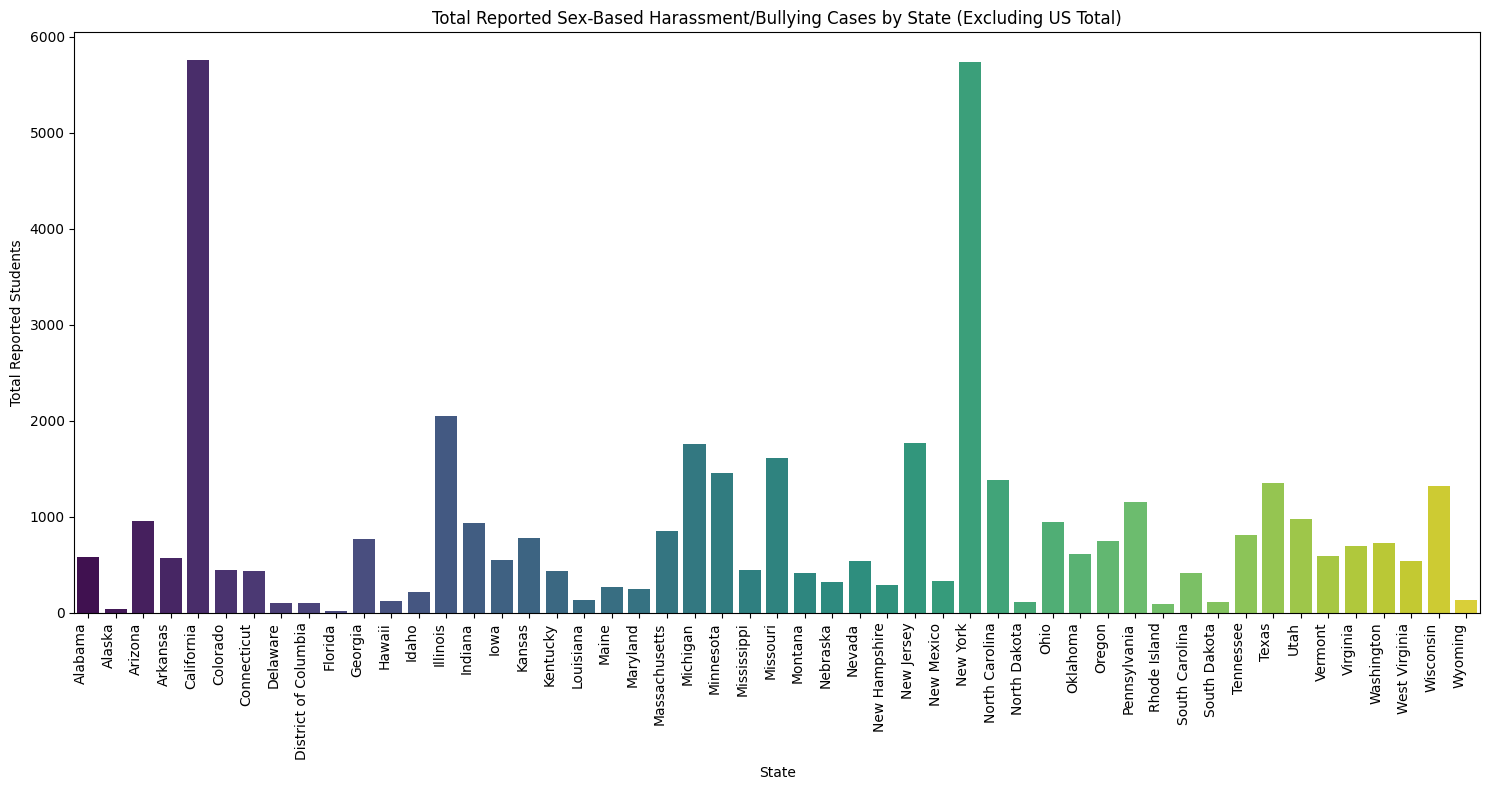

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out 'United States' to focus on individual states and ensure numeric type for plotting
data_states_reported_only = data_sex_reported_allegations[data_sex_reported_allegations['State'] != 'United States'].copy()
data_states_reported_only['Total_Students_Reported'] = pd.to_numeric(data_states_reported_only['Total_Students_Reported'], errors='coerce')

plt.figure(figsize=(15, 8))
sns.barplot(x='State', y='Total_Students_Reported', data=data_states_reported_only, palette='viridis')
plt.xlabel('State')
plt.ylabel('Total Reported Students')
plt.title('Total Reported Sex-Based Harassment/Bullying Cases by State (Excluding US Total)')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

#### Reported Cases for Students with Disabilities

/tmp/ipykernel_1120/364596948.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=disability_categories, y=disability_counts, palette='pastel')


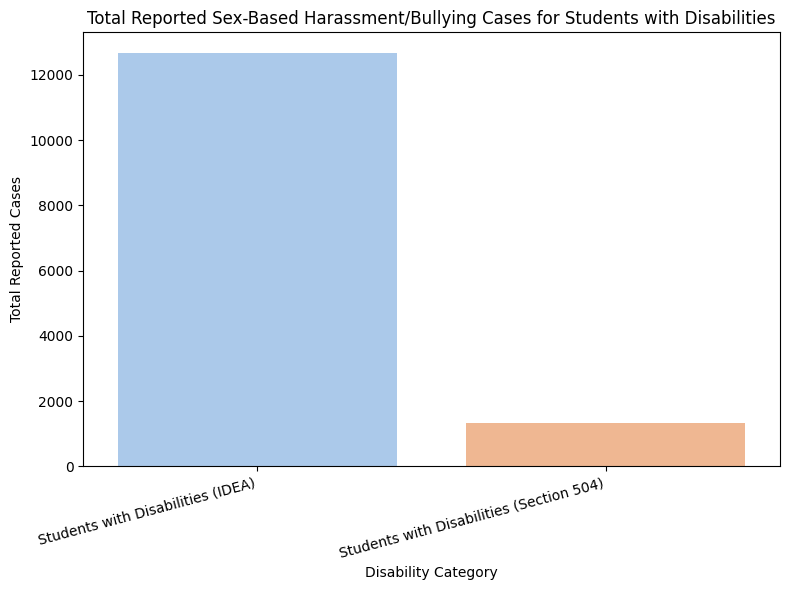

In [ ]:
# Sum reported cases for students with disabilities under IDEA and Section 504
reported_idea_count = data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Under_IDEA__Count'].sum()
reported_section504_count = data_sex_reported_allegations['Reported_Students_With_Disabilities_Served_Only_Under_Section_504__Count'].sum()

disability_categories = ['Students with Disabilities (IDEA)', 'Students with Disabilities (Section 504)']
disability_counts = [reported_idea_count, reported_section504_count]

plt.figure(figsize=(8, 6))
sns.barplot(x=disability_categories, y=disability_counts, palette='pastel')
plt.xlabel('Disability Category')
plt.ylabel('Total Reported Cases')
plt.title('Total Reported Sex-Based Harassment/Bullying Cases for Students with Disabilities')
plt.xticks(rotation=15, ha='right')
plt.tight_layout()
plt.show()

#### Reported Cases for English Language Learners

/tmp/ipykernel_1120/1773945319.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='State', y='Reported_English_Language_Learners__Count', data=data_states_ell_only, palette='cubehelix')


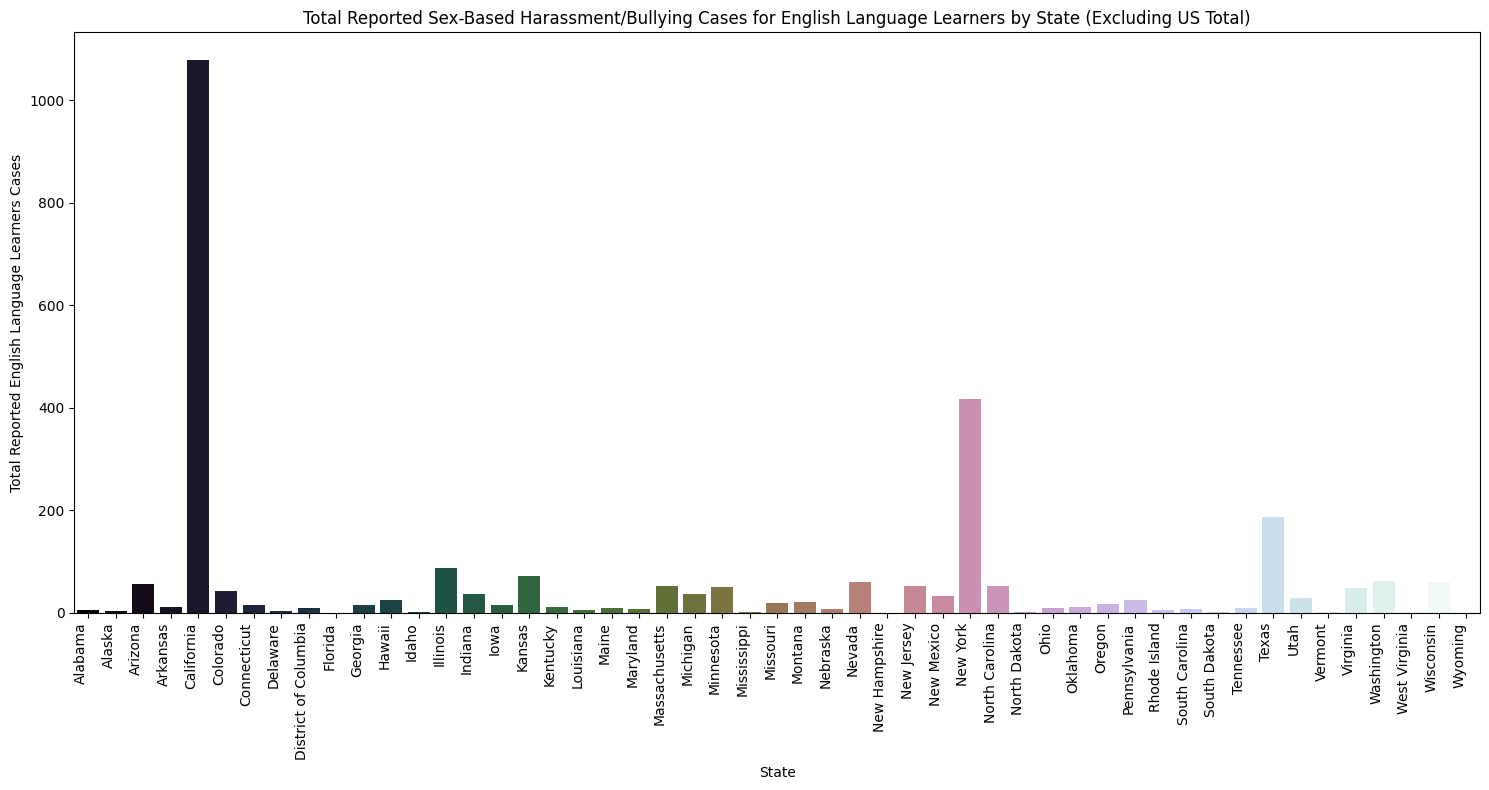

In [ ]:
# Filter out 'United States' for English Language Learners visualization
data_states_ell_only = data_sex_reported_allegations[data_sex_reported_allegations['State'] != 'United States'].copy()
data_states_ell_only['Reported_English_Language_Learners__Count'] = pd.to_numeric(data_states_ell_only['Reported_English_Language_Learners__Count'], errors='coerce')

plt.figure(figsize=(15, 8))
sns.barplot(x='State', y='Reported_English_Language_Learners__Count', data=data_states_ell_only, palette='cubehelix')
plt.xlabel('State')
plt.ylabel('Total Reported English Language Learners Cases')
plt.title('Total Reported Sex-Based Harassment/Bullying Cases for English Language Learners by State (Excluding US Total)')
plt.xticks(rotation=90, ha='right')
plt.tight_layout()
plt.show()

#### Reported Cases by Race/Ethnicity

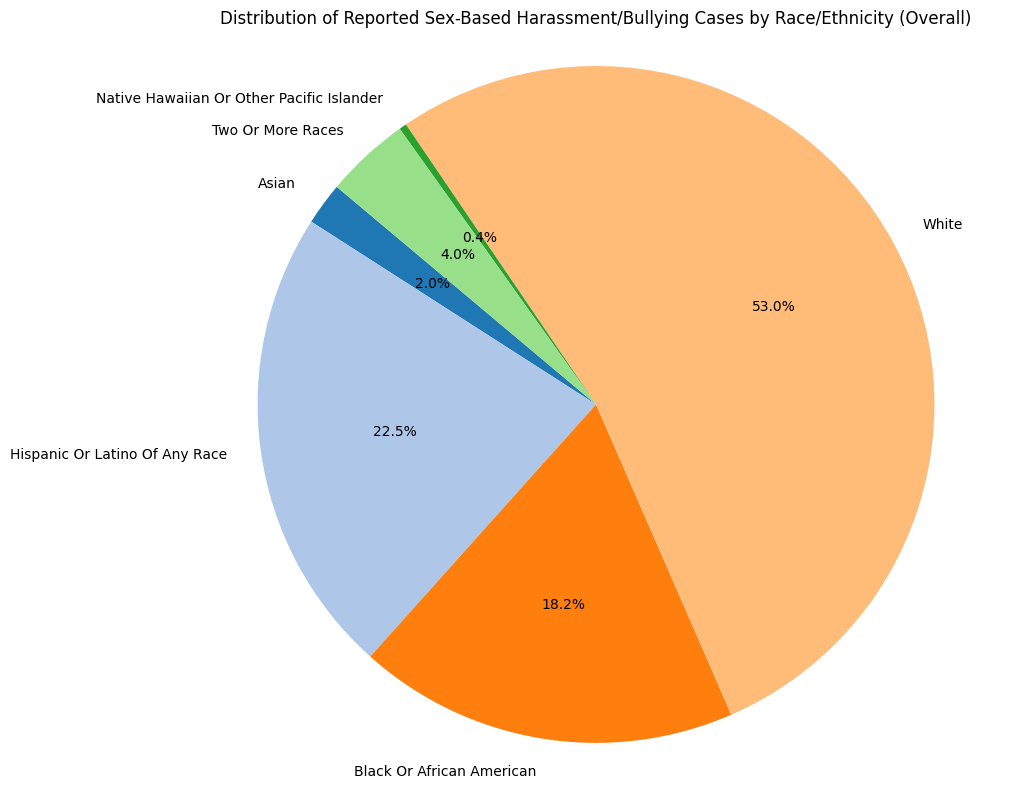

In [ ]:
import matplotlib.pyplot as plt

# The `reported_race_counts` dictionary is already available from previous analysis
race_labels = [k.replace('_', ' ').title() for k in reported_race_counts.keys()]
race_values = list(reported_race_counts.values())

plt.figure(figsize=(10, 8))
plt.pie(race_values, labels=race_labels, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('tab20'))
plt.title('Distribution of Reported Sex-Based Harassment/Bullying Cases by Race/Ethnicity (Overall)')
plt.axis('equal') # Equal aspect ratio ensures that pie is drawn as a circle.
plt.tight_layout()
plt.show()